<table>
        <td>
        <td><img src="https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/logo_ECI.png" width="400"/></td>
        <td>&nbsp;</td>
        <td>
            <h1 style="font-size:200%;color:blue;text-align:center">    <FONT COLOR="blue">  Reducción de Dimensionalidad </p> PCA </p> Análisis de Componentes Principales </p>    </FONT>         </h1></td>         
        <td>
            <tp><p style="font-size:99%;text-align:center">Diplomado Ciencia de Datos</p></tp>
            <tp><p style="font-size:115%;text-align:center">Curso 2026-2</p></tp>
            <tp><p style="font-size:115%;text-align:center">Prof. Fabián Sánchez</p></tp>
        </td>
    </tr>
</table>

In [ ]:
%%html
<center><marquee style='width: 60%; color: red'><b>✌ ¡Hola a todos y a todas! Un saludo... Bienvenidos a la clase de PCA✌ </b></marquee><center>

# <FONT SIZE=5 COLOR="purple"> 1. Análisis Exploratorio Multivariado </FONT>

En esta sesión revisaremos algunos elementos fundamentales de análisis exploratorio multivariado como:

- Tablas de contingencias

- Diagramas de dispersión

Por otro lado, revisaremos los conceptos y aplicación del análisis de componentes principales.


Primero cargaremos las librerías necesarias para el trabajo en este notebook

In [1]:
#para importar la librería pandas.
import pandas as pd
import numpy  as np

# librerías para gráficar
import matplotlib.pyplot as plt
import plotly.express    as px
import seaborn           as sns

# estandarizar los datos
from sklearn.preprocessing import StandardScaler

# importamos la librería para pca clásica
from sklearn.decomposition import PCA


Vamos a cargar algunos conjuntos de datos

In [ ]:
# importamos los datos
aptos = pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/apartamentos.csv")

In [ ]:
aptos.head()

,Unnamed: 0,precio,mt2,ubicacion,estrato,alcobas,banos,balcon,parqueadero,administracion,avaluo,terminado
0,1,79.0,43.16,norte,3,3,1,si,si,0.050,14.923002,no
1,2,93.0,56.92,norte,2,2,1,si,si,0.069,27.000000,si
2,3,100.0,66.40,norte,3,2,2,no,no,0.000,15.738427,no
3,4,123.0,61.85,norte,2,3,2,si,si,0.130,27.000000,no
4,5,135.0,89.80,norte,4,3,2,si,no,0.000,39.567000,si


In [ ]:
# cargamos el conjunto de datos diabetes
diabetes = pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/diabetes.csv")

In [ ]:
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
hogares = pd.read_csv("/content/datos_pca_4000_registros_20_variables.csv")

In [ ]:
hogares.head()

,ingreso_mensual_miles,ahorro_mensual_miles,gasto_educacion_miles,gasto_salud_miles,limite_tarjeta_miles,valor_vehiculo_millones,inversiones_millones,patrimonio_millones,gasto_alimentacion_miles,gasto_entretenimiento_miles,gasto_transporte_miles,compras_online_mes,salidas_restaurante_mes,horas_ocio_semana,viajes_anuales,area_vivienda_m2,numero_habitaciones,numero_banos,area_zona_social_m2,valor_vivienda_millones
0,3648.32,542.05,428.23,213.67,6089.67,57.71,5.64,253.86,809.93,389.30,540.19,8.96,6.64,18.71,3.12,102.49,3.13,2.45,35.43,491.27
1,2782.25,248.51,333.38,160.08,3633.94,39.07,3.87,107.99,749.76,314.25,343.90,5.25,3.83,13.18,1.77,84.16,2.45,2.02,23.55,343.41
2,5043.59,1125.77,699.72,367.50,8009.19,77.29,25.48,340.04,1136.64,512.29,637.94,12.07,8.67,25.11,5.33,119.98,3.56,2.99,47.16,600.62
3,4642.67,874.87,702.08,345.22,7464.88,78.35,29.92,346.52,765.67,257.31,401.31,6.62,4.45,16.47,2.62,97.97,3.19,2.38,33.81,403.41
4,3322.67,409.60,341.99,212.77,4433.75,45.72,6.25,201.81,1363.05,689.84,779.66,14.70,12.49,27.98,6.09,130.43,3.95,2.94,46.52,622.95


Vamos a calcular la matriz de correlación

**diabetes**

In [ ]:
diabetes.cov()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,11.354056,13.947131,9.214538,-4.390041,-28.555231,0.469774,-0.037426,21.570620,0.356618
Glucose,13.947131,1022.248314,94.430956,29.239183,1220.935799,55.726987,1.454875,99.082805,7.115079
BloodPressure,9.214538,94.430956,374.647271,64.029396,198.378412,43.004695,0.264638,54.523453,0.600697
SkinThickness,-4.390041,29.239183,64.029396,254.473245,802.979941,49.373869,0.972136,-21.381023,0.568747
Insulin,-28.555231,1220.935799,198.378412,802.979941,13281.180078,179.775172,7.066681,-57.143290,7.175671
BMI,0.469774,55.726987,43.004695,49.373869,179.775172,62.159984,0.367405,3.360330,1.100638
DiabetesPedigreeFunction,-0.037426,1.454875,0.264638,0.972136,7.066681,0.367405,0.109779,0.130772,0.027472
Age,21.570620,99.082805,54.523453,-21.381023,-57.143290,3.360330,0.130772,138.303046,1.336953
Outcome,0.356618,7.115079,0.600697,0.568747,7.175671,1.100638,0.027472,1.336953,0.227483


In [ ]:
diabetes.corr()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898
Glucose,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581
BloodPressure,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068
SkinThickness,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752
Insulin,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548
BMI,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695
DiabetesPedigreeFunction,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844
Age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356
Outcome,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000


In [ ]:
hogares.corr()

,ingreso_mensual_miles,ahorro_mensual_miles,gasto_educacion_miles,gasto_salud_miles,limite_tarjeta_miles,valor_vehiculo_millones,inversiones_millones,patrimonio_millones,gasto_alimentacion_miles,gasto_entretenimiento_miles,gasto_transporte_miles,compras_online_mes,salidas_restaurante_mes,horas_ocio_semana,viajes_anuales,area_vivienda_m2,numero_habitaciones,numero_banos,area_zona_social_m2,valor_vivienda_millones
ingreso_mensual_miles,1.000000,0.958086,0.958626,0.960249,0.958960,0.958963,0.953077,0.957459,0.017158,0.019635,0.012943,0.007234,0.018260,0.009651,0.010671,-0.013755,-0.016589,-0.009469,-0.007038,-0.016882
ahorro_mensual_miles,0.958086,1.000000,0.958288,0.960513,0.957770,0.959189,0.956957,0.958680,0.017013,0.018487,0.011845,0.006437,0.016522,0.009257,0.010560,-0.012580,-0.014690,-0.007740,-0.005424,-0.015326
gasto_educacion_miles,0.958626,0.958288,1.000000,0.958658,0.958665,0.957455,0.953058,0.958320,0.017872,0.019933,0.014215,0.008066,0.019111,0.009153,0.010412,-0.010689,-0.012159,-0.006331,-0.004098,-0.013504
gasto_salud_miles,0.960249,0.960513,0.958658,1.000000,0.960136,0.960738,0.953712,0.959684,0.010884,0.013678,0.006479,0.000814,0.012475,0.004578,0.006218,-0.014720,-0.015249,-0.010325,-0.008062,-0.016649
limite_tarjeta_miles,0.958960,0.957770,0.958665,0.960136,1.000000,0.958952,0.952956,0.959271,0.010620,0.014594,0.006213,0.000156,0.010440,0.002675,0.003945,-0.008732,-0.009352,-0.004905,-0.003301,-0.012056
valor_vehiculo_millones,0.958963,0.959189,0.957455,0.960738,0.958952,1.000000,0.953022,0.958137,0.008507,0.012195,0.002613,-0.000878,0.008103,0.001330,0.001520,-0.013990,-0.013730,-0.009344,-0.006687,-0.016604
inversiones_millones,0.953077,0.956957,0.953058,0.953712,0.952956,0.953022,1.000000,0.954387,0.015999,0.018814,0.011170,0.005508,0.016784,0.006354,0.010291,-0.014357,-0.013996,-0.008836,-0.007070,-0.017030
patrimonio_millones,0.957459,0.958680,0.958320,0.959684,0.959271,0.958137,0.954387,1.000000,0.011325,0.015035,0.007678,0.001567,0.013987,0.002597,0.004656,-0.008475,-0.010457,-0.004322,-0.002221,-0.011745
gasto_alimentacion_miles,0.017158,0.017013,0.017872,0.010884,0.010620,0.008507,0.015999,0.011325,1.000000,0.959615,0.959672,0.959774,0.959240,0.958332,0.958325,0.018394,0.008618,0.017913,0.021884,0.016177
gasto_entretenimiento_miles,0.019635,0.018487,0.019933,0.013678,0.014594,0.012195,0.018814,0.015035,0.959615,1.000000,0.957250,0.958411,0.959091,0.958186,0.959582,0.017892,0.009690,0.018925,0.022344,0.015235


Podemos hacer el mapa de calor de las correlaciones

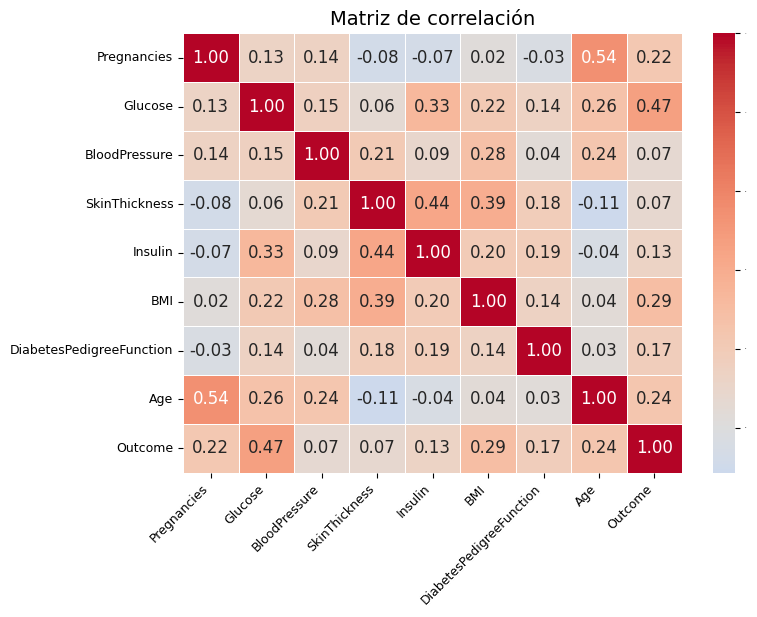

In [ ]:
# diagrama de correlación
plt.figure(figsize=(8, 6))

# Mapa de correlación
sns.heatmap(diabetes.corr(),                # matriz de correlaciones
            annot=True,                   # para colocar números adentro (correlaciones)
            fmt=".2f",                    # formato de los números
            cmap="coolwarm",              # colores frio-caliente
            center=0,                     # centro de la escala
            annot_kws={"size": 12},        # tamaño de los números
            linewidths=0.5)

# Tamaño de etiquetas
plt.xticks(fontsize=9, rotation=45, ha="right")
plt.yticks(fontsize=9, rotation=0)

plt.title("Matriz de correlación", fontsize=14)

plt.tight_layout()
plt.show()

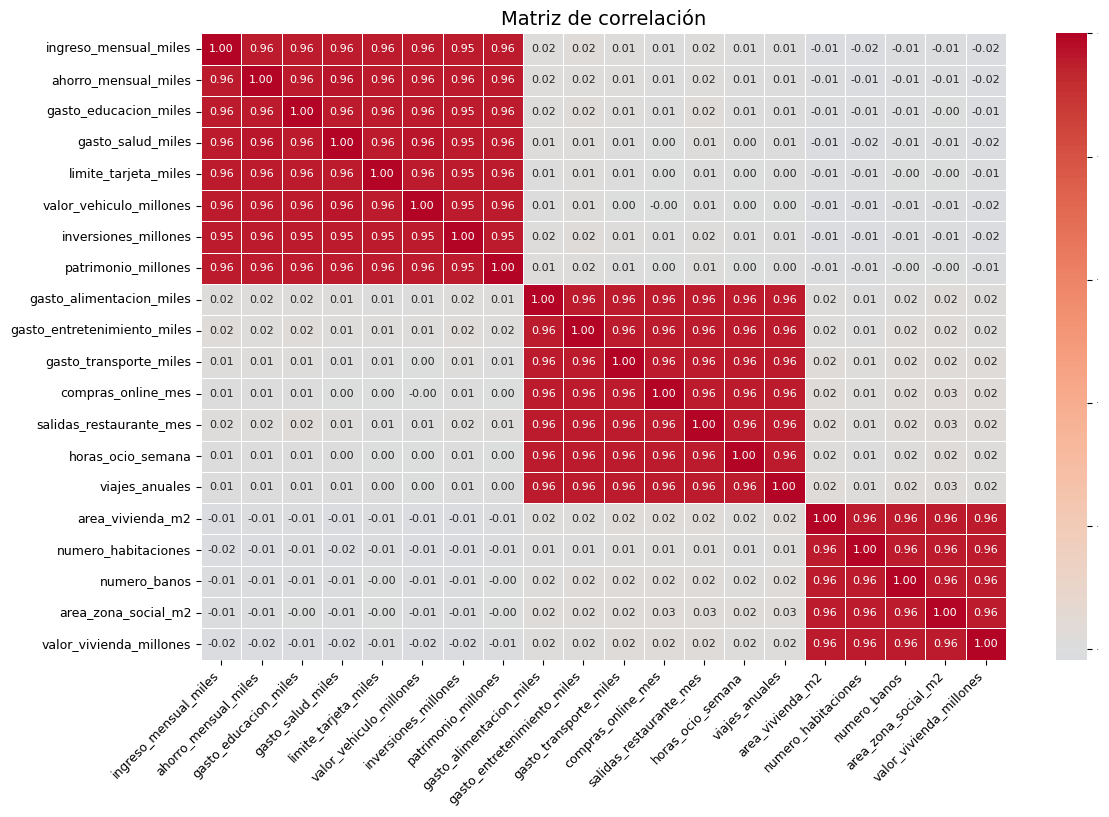

In [ ]:
# diagrama de correlación
plt.figure(figsize=(12, 8))

# Mapa de correlación
sns.heatmap(hogares.corr(),                # matriz de correlaciones
            annot=True,                   # para colocar números adentro (correlaciones)
            fmt=".2f",                    # formato de los números
            cmap="coolwarm",              # colores frio-caliente
            center=0,                     # centro de la escala
            annot_kws={"size": 8},        # tamaño de los números
            linewidths=0.5)

# Tamaño de etiquetas
plt.xticks(fontsize=9, rotation=45, ha="right")
plt.yticks(fontsize=9, rotation=0)

plt.title("Matriz de correlación", fontsize=14)

plt.tight_layout()
plt.show()

**Para el conjunto hogares**

In [ ]:
# diagrama de correlación
plt.figure(figsize=(12, 7))

# Mapa de correlación
sns.heatmap(hogares.corr(),                # matriz de correlaciones
            annot=True,                   # para colocar números adentro (correlaciones)
            fmt=".2f",                    # formato de los números
            cmap="coolwarm",              # colores frio-caliente
            center=0,                     # centro de la escala
            annot_kws={"size": 8},        # tamaño de los números
            linewidths=0.5)

# Tamaño de etiquetas
plt.xticks(fontsize=9, rotation=45, ha="right")
plt.yticks(fontsize=9, rotation=0)

plt.title("Matriz de correlación", fontsize=14)

plt.tight_layout()
plt.show()

# <FONT SIZE=5 COLOR="green"> 2. Análisis de Componentes Principales (PCA) </FONT>

El *Análisis de Componentes Principales (PCA)* es técnica estadística que se usa para reducir la cantidad de variables de un conjunto de datos, manteniendo la mayor cantidad posible de información (variabilidad).

<br>

<center><img src="https://github.com/Fabian830348/cursos/blob/9a46a11792dfe15cceefcb091ecb9d199091bfb9/Reduccion.png?raw=true" alt="centered image" width="550" height="350"></center><center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia </FONT> <figcaption></center>

Tenemos una representación de alta dimensión de los datos, que consta de muchas features (características), y deseamos encontrar una nueva forma de representar estos datos que resuma las características esenciales con menos features.  Deseamos por tanto, la reducción a pocas componentes con fines de visualización e interpretabilidad.

El análisis de componentes principales es un método que rota el conjunto de datos de tal manera que las características rotadas no están correlacionadas estadísticamente. Esta rotación suele ir seguida de la selección de solo un subconjunto de las "nuevas" features, de acuerdo con su importancia para la explicación los datos.

**Observación de cuando y cómo usar componentes principales**

- Cuando tenemos muchas variables, se deben revisar demasiados coeficientes de correlación.

- Puede que exista una fuerte correlación entre variables. Por ejemplo: en estudios medicos la presión sanguínea a la salidad del corazón y la salida de los pulmones están fuertemente relacionadas.

- La idea es reducir el número de variables.

- El análisis de componentes principales fue desarrollado por Pearson a finales del siglo XIX.

- Dadas $p$ variables, buscamos $m$ variables tal que $m < p$ que son combinación lineal de variables $p$, que no esten correlacionadas y que aporten la mayor cantidad de información posible o variabilidad de los datos.

- Si de entrada las variables iniciales no están correlacionadas no se aplica PCA.

## <FONT SIZE=5 COLOR="blue"> 2.1 Ideas del Desarrollo Matemático del PCA </FONT>

Sea $(x_1,x_2,x_3, \dots ,x_p)$ una series de variables y quiero un grupo de variables $(y_1,y_2, \dots y_n)$ con $(n<p)$ de variables no correlacionadas cuyas varianzas vayan decreciendo progresivamente.

Cada $y_j$ donde $j=1, \dots p$ es una combinación lineal de las $x_i$ originales, es decir,

$$y_j = a_{1j}x_1+a_{2j}x_2 + \dots + a_{pj}x_p $$

$$y_j = (a_{1j}, a_{2,j}, \dots a_{pj}).\begin{pmatrix} x_1 \\ x_2 \\ x_3 \\ . \\ .\\ .\\ x_p   \end{pmatrix}$$

$$y_j = \mathbf{a}{j}'\mathbf{x}$$

siendo $\mathbf{a_j}' = (a_{1j}, a_{2,j}, \dots a_{pj})$ un vector de constantes y

$$x = \begin{pmatrix} x_1 \\ x_2 \\ x_3 \\ . \\ .\\ .\\ x_p   \end{pmatrix}$$

Como queremos **maximizar la varianza**, la idea es aumentar los $(a_{ij})$ y como deben ser ortogonormales, deben cumplir

$$ \mathbf{a_j}'\mathbf{a_j} = \sum \limits_{k=1}^{p} a_{kj}^2=1$$

El primer componente se elije calculando $\mathbf{a_1}$ tal que $y_1$ tenga la mayor varianza posible, sujeta a la restricción que $\mathbf{a_1}'\mathbf{a_1}=1$.

El segundo componente principal se calcula obteniendo $\mathbf{a_2}$ tal que $y_2$ tenga una menor varianza que $y_1$ y no este correlacionada con $y_1$.

**¿Cuál es el proceso para hacer esto?** y **¿Qué tiene que ver con estadística?**

Quiero elegir $\mathbf{a_1}$ de modo que se maximice la varianza de $y_1$ con la restricción $\mathbf{a_1}'\mathbf{a_1}=1$

$$Var(y_1)= Var(\mathbf{a_1}' \mathbf{x})= \mathbf{a_1}'\sum a_1$$

Para maximizar esta función aplicamos el método de multiplicadores de Lagrange.

$$L(a_1) = a_1' \sum a_1 -\lambda (a_1' a_1 -1)$$

derivando e igualando a cero

$$\dfrac{\partial L}{ \partial a_1} = 2 \sum a_1 -2\lambda I a_1=0$$

$$(\sum - \lambda I) a_1 = 0$$

Luego $\det(\sum -\lambda I) = 0$ si queremos soluciones.

Con algunos cálculos podemos verificar que la matriz $\sum$ resulta ser la matriz de covarianzas de orden p. Además, esto quiere decir que $\lambda$ resulta ser un autovalor de la matriz $\sum$ . Si $\sum$ es la matriz de covarianzas de orden $p$ y si es definida positiva tendrá $p$ autovalores propios $\lambda_1 , \lambda_2 , \dots, \lambda_p$ tales que $\lambda_1 > \lambda_2 > \dots > \lambda_p$.

Luego,

$\sum a_1 = \lambda I a_1$,

y entonces

$$Var(y_1)= Var(a_1'x)=a_1'\sum a_1 = a_1' \lambda Ia_1 = \lambda a_1'a_1 = \lambda$$

Para maximizar la varianza de $y_1$ se tiene que tomar el mayor autovalor, digamos $\lambda_1$ y el correspondiente $a_1$.

Así podemos continuar, pero debemos colocar la condición $C(y_1,y_2)=0$

De esta manera encontraremos $Var(y_i) = \lambda_i$ para $i=1,2,3,\dots, p$.

$$Varianza Total = \sum \limits_{i=1}^{p} Var(y_i) = \sum \limits_{i=1}^{p} \lambda_i = traza(A).$$

Pero

$$traza(A) = traza(\sum) = \sum \limits_{i=1}^p Var(x_i)$$

Es decir, que la suma de las varianzas de las variables originales y la suma de las varianezas de las componentes son iguales. Luego, la varianza que recoge un componente principal

$$\dfrac{\lambda_i}{\sum \limits_{i=1}^p \lambda_i}= \dfrac{\lambda_i}{\sum \limits_{i=1}^p Var(x_i)}$$.

- En la práctica no nos quedamos con más de tres componentes, para poderlas gráficar.

**Comentarios**

- A menudo, las features variarán juntas, y parte de la variación en una está en realidad duplicada por la variación en otra. Esta técnica se usa para descubrir la forma en que las features numéricas covarían.

- La idea en PCA es combinar múltiples features numéricas en un conjunto más pequeño de features, que son combinaciones lineales ponderadas del conjunto original. Este "pequeño" conjunto de features (las componentes principales), "explica" la mayor parte de la variabilidad del total de features originales, reduciendo la dimensión de los datos.

- Los pesos utilizados para formar las componentes principales revelan las contribuciones relativas de las features originales a las nuevas componentes principales.

# <FONT SIZE=5 COLOR="purple">  3. Ejemplo 1. Hogares </FONT>

**Contexto del conjunto de datos**

El conjunto de datos representa información socioeconómica y de hábitos de consumo de 4.000 hogares o personas. El objetivo es analizar cómo un conjunto amplio de características observadas puede resumirse en un número reducido de dimensiones mediante Análisis de Componentes Principales (PCA).

**Descripción de las variables**

| Variable | Interpretación |
|---|---|
| `ingreso_mensual_miles` | Ingreso mensual, expresado en miles |
| `ahorro_mensual_miles` | Dinero ahorrado mensualmente |
| `gasto_educacion_miles` | Gasto mensual asociado con educación |
| `gasto_salud_miles` | Gasto mensual en salud |
| `limite_tarjeta_miles` | Cupo o límite disponible en tarjeta de crédito |
| `valor_vehiculo_millones` | Valor aproximado del vehículo |
| `inversiones_millones` | Valor acumulado en inversiones |
| `patrimonio_millones` | Patrimonio aproximado |
| `gasto_alimentacion_miles` | Gasto mensual en alimentación |
| `gasto_entretenimiento_miles` | Gasto mensual en entretenimiento |
| `gasto_transporte_miles` | Gasto mensual en transporte |
| `compras_online_mes` | Número de compras realizadas por internet al mes |
| `salidas_restaurante_mes` | Número de salidas a restaurantes al mes |
| `horas_ocio_semana` | Horas destinadas al ocio durante una semana |
| `viajes_anuales` | Número aproximado de viajes realizados al año |
| `area_vivienda_m2` | Área de la vivienda en metros cuadrados |
| `numero_habitaciones` | Número de habitaciones de la vivienda |
| `numero_banos` | Número de baños |
| `area_zona_social_m2` | Área destinada a sala, comedor u otras zonas sociales |
| `valor_vivienda_millones` | Valor estimado de la vivienda |


## <FONT SIZE=4 COLOR="blue">  3.1 Descripción rápida de los datos </FONT>

In [ ]:
# cabeza de los datos
hogares.head()

In [ ]:
# tamaño de los datos
hogares.shape

In [ ]:
# nombre de las variables
hogares.columns

In [ ]:
# información de los datos
hogares.info()

In [ ]:
# estadísticas descriptiva
hogares.describe()

**escalar los datos**

In [ ]:
# escalar los datos
hogares_std = StandardScaler().fit_transform(hogares)
hogares_std[0:5]

In [ ]:
# revisamos la matriz de correlaciones
pd.DataFrame(hogares_std ,
             index = hogares.index ,
             columns = hogares.columns) #.corr()

In [ ]:
# revisamos la matriz de correlaciones
pd.DataFrame(hogares_std ,
             index = hogares.index ,
             columns = hogares.columns).corr()

## <FONT SIZE=4 COLOR="blue">  3.2 Aplicar PCA y analizar </FONT>

In [ ]:
# Definimos el objeto PCA y determinamos el número de componentes principales que deseamos.
pca_hogares_2 = PCA(n_components=2)            # Otra opcion pca = PCA(n_components = 0.85).
pca_hogares_2.fit(hogares_std)                      # Ajuste ese PCA a los datos estandarizados.

Revisemos qué información tenemos del PCA con dos componentes

**1. Para revisar los valores propios y la varianza explicada**

In [ ]:
# vectores propios y valores propios
pca_hogares_2.explained_variance_

Es decir, los dos valores propios más grandes son

- $\lambda_1 = 7.71$

- $\lambda_2 = 6.75$

In [ ]:
# variabilidad de cada valor propio
pca_hogares_2.explained_variance_ratio_

Esto significa que la primera componente $PC1$ concentra el $38.5\%$ de variabilidad de los datos y la componente $PC2$ concentra el $33.7$ \%.

2. **Para revisar lo vectores propios asociados**

In [ ]:
pca_hogares_2.components_

In [ ]:
eigenvectors = pd.DataFrame(pca_hogares_2.components_,
                            columns=hogares.columns,
                            index=['PC1', 'PC2'])

eigenvectors

In [ ]:
# mapa de calor de estos valores
plt.figure(figsize=(12, 9))
sns.heatmap(pca_hogares_2.components_,                             # las componentes del PCA
            xticklabels=hogares.columns,                     # en x van las columnas del dataframe original
            yticklabels=["CP1", "CP2"],                  # en y van las componentes CP1 y CP2
            cmap = "coolwarm",                           # mapa de calor
            fmt=".1f",                                   # formato de los valores
            annot=True,
            annot_kws={"size": 8})                                  # para que muestre valores
plt.show()

## <FONT SIZE=4 COLOR="blue">  3.3 Biplots </FONT>

Un biplot es una herramienta visual muy útil cuando se hace un Análisis de Componentes Principales (PCA), ya que permite visualizar:

  - Los individuos/observaciones (como puntos)

  - Las variables originales (como flechas)

Para los vectores (variables), nos fijamos en su longitud y en el ángulo con respecto a los ejes de las componentes principales y entre ellos mismos:

**Ángulo**:

- Cuanto más paralelo es un vector al eje de una componente, más ha contribuido a la creación de la misma. Con ello se obtiene información sobre qué variable(s) ha sido más determinante para crear cada componente, y si entre las variables (y cuales) hay correlaciones.

- Ángulos pequeños entre vectores representa alta correlación entre las variables implicadas (observaciones con valores altos en una de esas variables tendrá valores altos en la variable o variables correlacionadas)

- Ángulos rectos representan falta de correlación, y ángulos opuestos representan correlación negativa (una observación con valores altos en una de las variables irá acompañado de valores bajos en la otra).

**Longitud**: cuanto mayor la longitud de un vector relacionado con x variable (en un rango normalizado de 0 a 1), mayor variabilidad de dicha variable está contenida en la representación de las dos componentes del biplot, es decir, mejor está representada su información en el gráfico.

In [ ]:
# instalar la librería para hacer pca y biplots
!pip install pca

In [ ]:
# llamar la librería
from pca import pca

In [ ]:
model_hogares = pca(n_components=2, normalize=True)
out = model_hogares.fit_transform(hogares)

In [ ]:
# para hacer el biplot
fig, ax = model_hogares.biplot(label=True,
                               legend=True,
                               figsize=(12, 10))

In [ ]:
# Si no queremos agregar los puntos
fig, ax = model_hogares.biplot(cmap=None,
                               label=False,
                               legend=False,
                               figsize=(10, 6))

# <FONT SIZE=5 COLOR="purple">  4. Ejemplo 2. Carbon </FONT>

Vamos a trabajar con el conjunto de datos (clásico de internet) denominado **Global_Carbon_Budget_2018**.

Referencia: https://essd.copernicus.org/articles/10/2141/2018/?utm_source=chatgpt.com

https://essd.copernicus.org/articles/10/2141/2018/

***Contexto:***

El Global Carbon Budget es un informe anual que cuantifica los flujos globales de dióxido de carbono (CO₂) en la atmósfera. Lo elabora el consorcio científico Global Carbon Project (GCP). Su objetivo principal es monitorear:

 - Emisiones humanas de CO₂ (por quema de combustibles fósiles, uso del suelo, etc.)

 - Absorción de CO₂ por océanos y ecosistemas terrestres.

 - Crecimiento del CO₂ atmosférico.

 - Desequilibrios en el presupuesto global de carbono.

## <FONT SIZE=4 COLOR="blue">  4.1 Cargar y explorar los datos </FONT>

In [ ]:
carbon = pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/global_carbon_budget_2018.csv", sep = ";", index_col = "Year", decimal=",")
carbon.head()

,fossil fuel and industry,land-use change emissions,atmospheric growth,ocean sink,land sink,budget imbalance
Year,,,,,,
1750,NaN,NaN,-0.08,NaN,0.09,NaN
1751,0.0,NaN,-0.07,NaN,-0.53,NaN
1752,0.0,NaN,-0.07,NaN,-0.27,NaN
1753,0.0,NaN,-0.07,NaN,-0.17,NaN
1754,0.0,NaN,-0.06,NaN,-0.33,NaN


Veamos el significado de las variables

<center>

|feature|Traducción|Significado|
|:---|---:|---:|
|fossil fuel and industry|Combustible fósil e industría|Emisiones de CO₂ por uso de combustibles fósiles y procesos industriales.|
|land-use change emissions|emisiones de cambio de uso de la tierra|Emisiones por deforestación, agricultura, incendios, etc.|
|atmospheric growth|crecimiento atmosférico|Aumento neto del CO₂ en la atmósfera (lo que no fue absorbido).|
|ocean sink|sumidero del oceano|CO₂ absorbido por los océanos (sumidero natural).|
|land sink|sumidero de tierra|	CO₂ absorbido por ecosistemas terrestres (bosques, suelos, etc.).|
|budget imbalance|desequilibrio presupuestario|Diferencia entre las emisiones totales y los sumideros (lo que "no cuadra").

</center>

Antes de aplicar cualquier método de machine learning para predicciones o de reducción de dimensionalidad, debemos hacer una pequeña exploración del conjunto de datos.

In [ ]:
# tamaño del data.frame
carbon.shape

(268, 6)

In [ ]:
# información del conjunto de datos
carbon.info()

<class 'pandas.core.frame.DataFrame'>
Index: 268 entries, 1750 to 2017
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   fossil fuel and industry   267 non-null    float64
 1   land-use change emissions  168 non-null    float64
 2   atmospheric growth         255 non-null    float64
 3   ocean sink                 230 non-null    float64
 4   land sink                  268 non-null    float64
 5   budget imbalance           155 non-null    float64
dtypes: float64(6)
memory usage: 14.7 KB


In [ ]:
# existencia de NA (datos faltantes)
carbon.isna().sum()

,0
fossil fuel and industry,1
land-use change emissions,100
atmospheric growth,13
ocean sink,38
land sink,0
budget imbalance,113


In [ ]:
# veamos una descripción de los datos
carbon.describe()

,fossil fuel and industry,land-use change emissions,atmospheric growth,ocean sink,land sink,budget imbalance
count,267.000000,168.000000,255.000000,230.000000,268.000000,155.000000
mean,1.609288,1.198631,0.811255,0.673087,0.809590,0.133161
std,2.565235,0.293249,1.001325,0.667772,0.980536,0.801828
min,0.000000,0.670000,-0.100000,0.070000,-0.600000,-2.310000
25%,0.010000,1.017500,0.205000,0.170000,0.170000,-0.420000
50%,0.280000,1.215000,0.470000,0.465000,0.560000,0.100000
75%,1.700000,1.390000,0.790000,0.737500,1.067500,0.635000
max,9.870000,1.810000,3.480000,2.650000,4.250000,2.350000


Ahora, calculamos las correlaciones

In [ ]:
carbon.corr()

,fossil fuel and industry,land-use change emissions,atmospheric growth,ocean sink,land sink,budget imbalance
fossil fuel and industry,1.000000,0.422327,0.970454,0.989326,0.817726,-0.053529
land-use change emissions,0.422327,1.000000,0.293668,0.400724,0.333566,0.401439
atmospheric growth,0.970454,0.293668,1.000000,0.961985,0.749495,-0.184363
ocean sink,0.989326,0.400724,0.961985,1.000000,0.784680,-0.078913
land sink,0.817726,0.333566,0.749495,0.784680,1.000000,-0.594513
budget imbalance,-0.053529,0.401439,-0.184363,-0.078913,-0.594513,1.000000


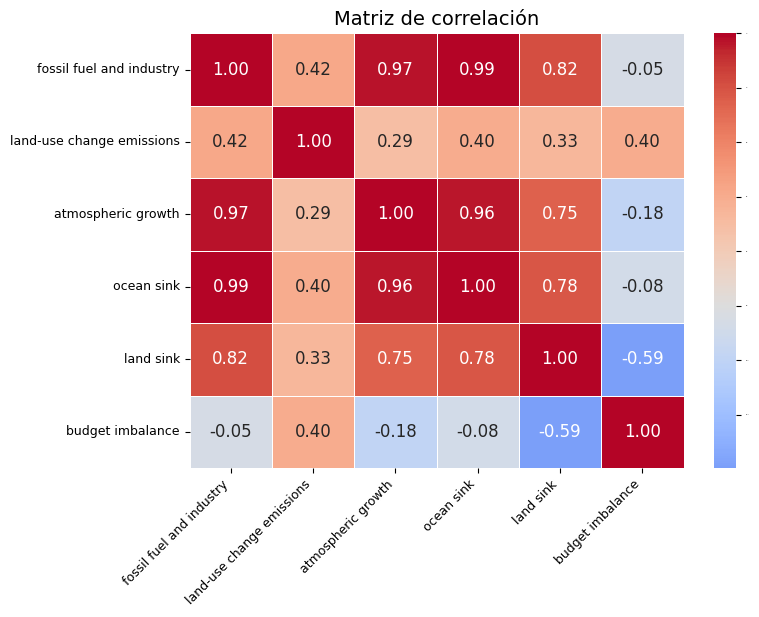

In [ ]:
# diagrama de correlación
plt.figure(figsize=(8, 6))

# Mapa de correlación
sns.heatmap(carbon.corr(),                # matriz de correlaciones
            annot=True,                   # para colocar números adentro (correlaciones)
            fmt=".2f",                    # formato de los números
            cmap="coolwarm",              # colores frio-caliente
            center=0,                     # centro de la escala
            annot_kws={"size": 12},        # tamaño de los números
            linewidths=0.5)

# Tamaño de etiquetas
plt.xticks(fontsize=9, rotation=45, ha="right")
plt.yticks(fontsize=9, rotation=0)

plt.title("Matriz de correlación", fontsize=14)

plt.tight_layout()
plt.show()

Vamos a explorar algunas relaciones entre variables

In [ ]:
# fossil vs ocean
fig = px.scatter(carbon,  # datos
                 x="fossil fuel and industry", # variable x
                 y="ocean sink",  #variable y
                 trendline='ols', # línea de tendencia (mínimos cuadrados)
                 trendline_color_override='red')
fig.show()

In [ ]:
# fossil and land
fig = px.scatter(carbon,
                 x="fossil fuel and industry",
                 y="land sink",
                 trendline = "ols",
                 trendline_color_override = "red"
                 )
fig.show()

Observamos que las tres variables anteriores tienen información altamente correlacionada.

la demás exploración se deja al lector...

## <FONT SIZE=4 COLOR="blue">  4.2 Aplicar PCA </FONT>



Importamos las librerías

In [ ]:
# importamos la librería para pca clásica
from sklearn.decomposition import PCA
# importamos el escalador estándar
from sklearn.preprocessing import StandardScaler

**Cargar y organizar los datos**

Ya tenemos los datos. Observamos que hay datos faltantes. En este ejercicio vamos a eliminarlos. Sin embargo, esto no es recomendable y se debe examinar el motivo y naturaleza de los datos faltantes.

In [ ]:
# Debemos trabajar con datos no nulos. En esta ocasión los vamos a omitir !!
carbon_sin_na = carbon.dropna()
carbon_sin_na.info()

<class 'pandas.core.frame.DataFrame'>
Index: 155 entries, 1850 to 2004
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   fossil fuel and industry   155 non-null    float64
 1   land-use change emissions  155 non-null    float64
 2   atmospheric growth         155 non-null    float64
 3   ocean sink                 155 non-null    float64
 4   land sink                  155 non-null    float64
 5   budget imbalance           155 non-null    float64
dtypes: float64(6)
memory usage: 8.5 KB


In [ ]:
# vemos la cabeza de los datos
carbon_sin_na.head()

,fossil fuel and industry,land-use change emissions,atmospheric growth,ocean sink,land sink,budget imbalance
Year,,,,,,
1850,0.05,0.69,0.19,0.16,0.56,-0.17
1851,0.05,0.69,0.13,0.17,-0.02,0.47
1852,0.06,0.70,0.07,0.17,0.27,0.25
1853,0.06,0.70,0.01,0.17,0.08,0.50
1854,0.07,0.70,-0.04,0.17,0.18,0.46


Vamos a escalar los datos.

In [ ]:
# escalar los datos
carbon_std = StandardScaler().fit_transform(carbon_sin_na)
carbon_std[0:5]

array([[-0.89420695, -1.67417522, -0.91627018, -1.10863963, -0.48848619,
        -0.37931322],
       [-0.89420695, -1.67417522, -0.97046322, -1.0922067 , -1.12071924,
         0.42145017],
       [-0.88962051, -1.64019183, -1.02465625, -1.0922067 , -0.80460271,
         0.14618775],
       [-0.88962051, -1.64019183, -1.07884928, -1.0922067 , -1.01171354,
         0.45898595],
       [-0.88503408, -1.64019183, -1.12401015, -1.0922067 , -0.90270784,
         0.40893824]])

In [ ]:
# revisamos la matriz de correlaciones
pd.DataFrame(carbon_std,
             index = carbon_sin_na.index ,
             columns = carbon_sin_na.columns)

,fossil fuel and industry,land-use change emissions,atmospheric growth,ocean sink,land sink,budget imbalance
Year,,,,,,
1850,-0.894207,-1.674175,-0.916270,-1.108640,-0.488486,-0.379313
1851,-0.894207,-1.674175,-0.970463,-1.092207,-1.120719,0.421450
1852,-0.889621,-1.640192,-1.024656,-1.092207,-0.804603,0.146188
1853,-0.889621,-1.640192,-1.078849,-1.092207,-1.011714,0.458986
1854,-0.885034,-1.640192,-1.124010,-1.092207,-0.902708,0.408938
...,...,...,...,...,...,...
2000,2.155773,0.466778,2.028218,2.358708,3.250409,-2.281126
2001,2.229156,-0.008989,2.037250,2.358708,1.528119,-0.291730
2002,2.275020,0.534745,2.046282,2.457306,-0.106966,1.822786


In [ ]:
# revisamos la matriz de correlaciones
pd.DataFrame(carbon_std,
             index = carbon_sin_na.index ,
             columns = carbon_sin_na.columns).corr()

,fossil fuel and industry,land-use change emissions,atmospheric growth,ocean sink,land sink,budget imbalance
fossil fuel and industry,1.000000,0.404771,0.969705,0.988774,0.727075,-0.053529
land-use change emissions,0.404771,1.000000,0.293668,0.426617,0.295279,0.401439
atmospheric growth,0.969705,0.293668,1.000000,0.966279,0.711759,-0.184363
ocean sink,0.988774,0.426617,0.966279,1.000000,0.726006,-0.078913
land sink,0.727075,0.295279,0.711759,0.726006,1.000000,-0.594513
budget imbalance,-0.053529,0.401439,-0.184363,-0.078913,-0.594513,1.000000


Ahora, definimos el PCA con un número de componentes dado

In [ ]:
# Definimos el objeto PCA y determinamos el número de componentes principales que deseamos.
pca_carbon = PCA(n_components=2)               # Otra opcion pca = PCA(n_components = 0.85).
pca_carbon.fit(carbon_std)                      # Ajuste ese PCA a los datos estandarizados.

PCA(n_components=2)

In [ ]:
carbon.head()

,fossil fuel and industry,land-use change emissions,atmospheric growth,ocean sink,land sink,budget imbalance
Year,,,,,,
1750,NaN,NaN,-0.08,NaN,0.09,NaN
1751,0.0,NaN,-0.07,NaN,-0.53,NaN
1752,0.0,NaN,-0.07,NaN,-0.27,NaN
1753,0.0,NaN,-0.07,NaN,-0.17,NaN
1754,0.0,NaN,-0.06,NaN,-0.33,NaN


Exploremos que hace el modelo

## <FONT SIZE=4 COLOR="blue">  4.3 Analizar el modelo </FONT>

**1. Para revisar los valores propios y la varianza explicada**


In [ ]:
# vectores propios y valores propios
pca_carbon.explained_variance_

array([3.80651605, 1.52827016])

Es decir, los dos valores propios más grandes son

- $\lambda_1 = 3.80$

- $\lambda_2 = 1.52$

In [ ]:
# variabilidad de cada valor propio
pca_carbon.explained_variance_ratio_

array([0.63032631, 0.25306839])

In [ ]:
pca_carbon.explained_variance_ratio_.cumsum()

array([0.63032631, 0.88339471])

Esto significa que la primera componente $PC1$ concentra el 63.03% de variabilidad de los datos y la componente $PC2$ concentra el 25.3%.

In [ ]:
# para calcular el total: Cantidad de varianza retenida por las 2 primeras componentes principales.
ratio = np.sum(pca_carbon.explained_variance_ratio_)
print(f"\nLa cantidad de variabilidad retenida por las 2 primeras componentes es {ratio*100:.3f}%")


La cantidad de variabilidad retenida por las 2 primeras componentes es 88.339%


2. **Para revisar lo vectores propios asociados**

In [ ]:
pca_carbon.components_

array([[ 0.49949296,  0.23098062,  0.49192489,  0.50104394,  0.43654799,
        -0.11638497],
       [ 0.09659132,  0.56232404, -0.01042547,  0.09219622, -0.29978323,
         0.75893542]])

In [ ]:
eigenvectors = pd.DataFrame(pca_carbon.components_,
                            columns=carbon.columns,
                            index=['PC1', 'PC2'])

eigenvectors

,fossil fuel and industry,land-use change emissions,atmospheric growth,ocean sink,land sink,budget imbalance
PC1,0.499493,0.230981,0.491925,0.501044,0.436548,-0.116385
PC2,0.096591,0.562324,-0.010425,0.092196,-0.299783,0.758935


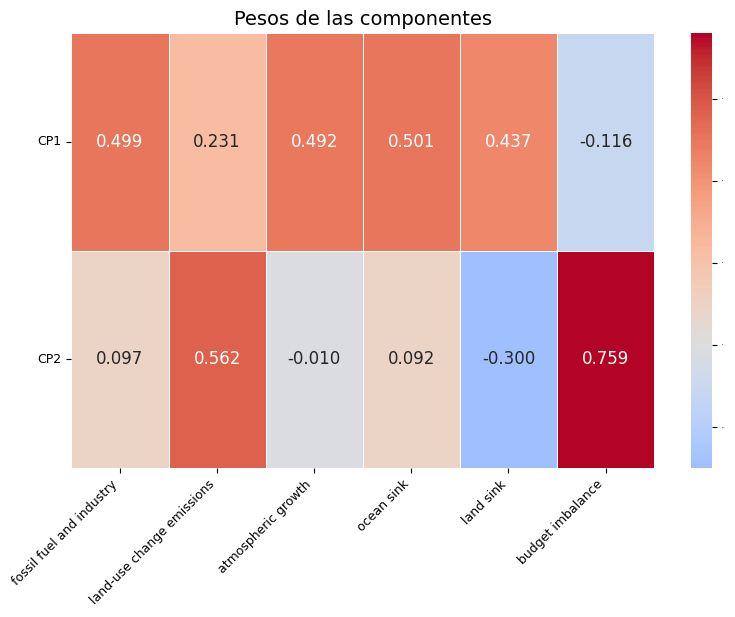

In [ ]:
# diagrama de correlación
plt.figure(figsize=(8, 6))

# pesos de las componentes
sns.heatmap(pca_carbon.components_,
            xticklabels=carbon.columns,
            yticklabels=["CP1", "CP2"],
            annot=True,                   # para colocar números adentro (correlaciones)
            fmt=".3f",                    # formato de los números
            cmap="coolwarm",              # colores frio-caliente
            center=0,                     # centro de la escala
            annot_kws={"size": 12},        # tamaño de los números
            linewidths=0.5)

# Tamaño de etiquetas
plt.xticks(fontsize=9, rotation=45, ha="right")
plt.yticks(fontsize=9, rotation=0)

plt.title("Pesos de las componentes", fontsize=14)

plt.tight_layout()
plt.show()

Lo que significa que:

$$PC1 = 0.49(fossil) + 0.23(land) + 0.49(atmosphere) + 0.5(ocean) + 0.44 (land sink) -0.12(budget) $$

de manera similar para PC2

Observe que el mayor peso lo tienen

PC1 :*fossil* y *atmosphere* y *ocean*

PC2 : *budget* y *land*

**3. Las proyecciones de los datos en esas dos componentes**

$$ pca.transform(datos\_escalados)$$

**pcs.transform** se usa para proyectar los datos originales en el nuevo espacio reducido por el PCA.

In [ ]:
carbon_sin_na.head()

,fossil fuel and industry,land-use change emissions,atmospheric growth,ocean sink,land sink,budget imbalance
Year,,,,,,
1850,0.05,0.69,0.19,0.16,0.56,-0.17
1851,0.05,0.69,0.13,0.17,-0.02,0.47
1852,0.06,0.70,0.07,0.17,0.27,0.25
1853,0.06,0.70,0.01,0.17,0.08,0.50
1854,0.07,0.70,-0.04,0.17,0.18,0.46


In [ ]:
carbon.corr()

,fossil fuel and industry,land-use change emissions,atmospheric growth,ocean sink,land sink,budget imbalance
fossil fuel and industry,1.000000,0.422327,0.970454,0.989326,0.817726,-0.053529
land-use change emissions,0.422327,1.000000,0.293668,0.400724,0.333566,0.401439
atmospheric growth,0.970454,0.293668,1.000000,0.961985,0.749495,-0.184363
ocean sink,0.989326,0.400724,0.961985,1.000000,0.784680,-0.078913
land sink,0.817726,0.333566,0.749495,0.784680,1.000000,-0.594513
budget imbalance,-0.053529,0.401439,-0.184363,-0.078913,-0.594513,1.000000


In [ ]:
# transformar los datos originales en función de las componentes
pca_carbon_proj = pca_carbon.transform(carbon_std)

In [ ]:
proyecciones = pd.DataFrame(pca_carbon_proj,
                            columns = ['PC1', 'PC2'],
                            index   = carbon_sin_na.index)
proyecciones.head(10)

,PC1,PC2
Year,,
1850,-2.008667,-1.261896
1851,-2.396289,-0.462555
1852,-2.242771,-0.746110
1853,-2.396249,-0.446063
1854,-2.362762,-0.515811
1855,-2.383337,-0.424952
1856,-2.090406,-1.014900
1857,-1.925483,-1.297427
1858,-2.301427,-0.510894


Exploremos la correlación de estas dos componentes, que deberían cumplir

- La diagonal igual a 1, porque es la misma variable

- La correlación entre las componentes deber tender a cero.

In [ ]:
proyecciones.corr()

,PC1,PC2
PC1,1.000000e+00,-2.977042e-16
PC2,-2.977042e-16,1.000000e+00


In [ ]:
round(proyecciones.corr(), 3)

,PC1,PC2
PC1,1.0,-0.0
PC2,-0.0,1.0


tienen que tener correlaciones casi nulas entre las variables diferentes.

**Hagamos el mismo ejercicio con tres componentes**

In [ ]:
# Definimos el objeto PCA y determinamos el número de componentes principales que deseamos.
pca_carbon_3 = PCA(n_components=3)               # Otra opcion pca = PCA(n_components = 0.85).
pca_carbon_3.fit(carbon_std)                          # Ajuste ese PCA a los datos estandarizados.

PCA(n_components=3)

In [ ]:
# valores propios
pca_carbon_3.explained_variance_

array([3.80651605, 1.52827016, 0.60969087])

In [ ]:
# varianza explicada
pca_carbon_3.explained_variance_ratio_

array([0.63032631, 0.25306839, 0.10095956])

In [ ]:
pca_carbon_3.explained_variance_ratio_.cumsum()

array([0.63032631, 0.88339471, 0.98435427])

In [ ]:
# las componentes
pca_carbon_3.components_

array([[ 0.49949296,  0.23098062,  0.49192489,  0.50104394,  0.43654799,
        -0.11638497],
       [ 0.09659132,  0.56232404, -0.01042547,  0.09219622, -0.29978323,
         0.75893542],
       [-0.25021475,  0.7150887 , -0.32159822, -0.20972957,  0.42907782,
        -0.30744276]])

In [ ]:
eigenvectors_3 = pd.DataFrame(pca_carbon_3.components_,
                            columns=carbon.columns,
                            index=["PC1", "PC2", "PC3"])

eigenvectors_3

,fossil fuel and industry,land-use change emissions,atmospheric growth,ocean sink,land sink,budget imbalance
PC1,0.499493,0.230981,0.491925,0.501044,0.436548,-0.116385
PC2,0.096591,0.562324,-0.010425,0.092196,-0.299783,0.758935
PC3,-0.250215,0.715089,-0.321598,-0.209730,0.429078,-0.307443


In [ ]:
proyecciones3 = pd.DataFrame(pca_carbon_3.transform(carbon_std),
                             columns = ["PC1", "PC2","PC3"],
                             index   = carbon_sin_na.index
)
proyecciones3.head(6)

,PC1,PC2,PC3
Year,,,
1850,-2.008667,-1.261896,-0.539236
1851,-2.396289,-0.462555,-1.042720
1852,-2.242771,-0.746110,-0.781872
1853,-2.396249,-0.446063,-0.949478
1854,-2.362762,-0.515811,-0.873943
1855,-2.383337,-0.424952,-0.889068


In [ ]:
round(proyecciones3.corr(), 3)

,PC1,PC2,PC3
PC1,1.0,-0.0,-0.0
PC2,-0.0,1.0,0.0
PC3,-0.0,0.0,1.0


------------------------------------------
Porcentaje de varianza explicada acumulada
------------------------------------------
[0.63032631 0.88339471 0.98435427]


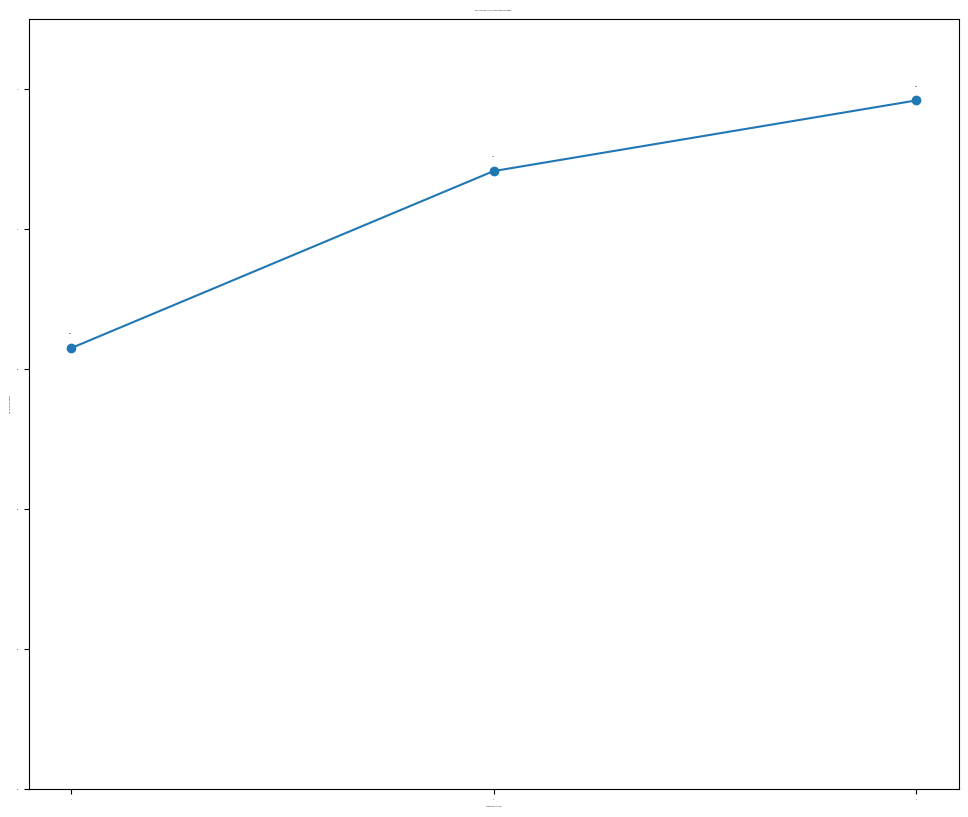

In [ ]:
# Porcentaje de varianza explicada acumulada
# ==============================================================================
prop_varianza_acum = pca_carbon_3.explained_variance_ratio_.cumsum()
print('------------------------------------------')
print('Porcentaje de varianza explicada acumulada')
print('------------------------------------------')
print(prop_varianza_acum)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 10))
ax.plot(
    np.arange(len(proyecciones3.columns)) + 1,
    prop_varianza_acum,
    marker = 'o'
)

for x, y in zip(np.arange(len(proyecciones3.columns)) + 1, prop_varianza_acum): # hacer las proyecciones
    label = round(y, 2)
    ax.annotate(
        label,
        (x,y),
        textcoords="offset points",
        xytext=(0,10),
        ha='center'
    )

ax.set_ylim(0, 1.1)
ax.set_xticks(np.arange(pca_carbon_3.n_components_) + 1)
ax.set_title('Porcentaje de varianza explicada acumulada')
ax.set_xlabel('Componente principal')
ax.set_ylabel('Por. varianza acumulada');

A continuación, revisaremos una repreentación gráfica útil en el análisis de componentes principales

Vamos a ver los pasos para gráficar un Biplot

## <FONT SIZE=4 COLOR="blue">  4.4 Los Biplots </FONT>

Un biplot es una herramienta visual muy útil cuando se hace un Análisis de Componentes Principales (PCA), ya que permite visualizar:

  - Los individuos/observaciones (como puntos)

  - Las variables originales (como flechas)

Para los vectores (variables), nos fijamos en su longitud y en el ángulo con respecto a los ejes de las componentes principales y entre ellos mismos:

**Ángulo**:

- Cuanto más paralelo es un vector al eje de una componente, más ha contribuido a la creación de la misma. Con ello se obtiene información sobre qué variable(s) ha sido más determinante para crear cada componente, y si entre las variables (y cuales) hay correlaciones.

- Ángulos pequeños entre vectores representa alta correlación entre las variables implicadas (observaciones con valores altos en una de esas variables tendrá valores altos en la variable o variables correlacionadas)

- Ángulos rectos representan falta de correlación, y ángulos opuestos representan correlación negativa (una observación con valores altos en una de las variables irá acompañado de valores bajos en la otra).

**Longitud**: cuanto mayor la longitud de un vector relacionado con x variable (en un rango normalizado de 0 a 1), mayor variabilidad de dicha variable está contenida en la representación de las dos componentes del biplot, es decir, mejor está representada su información en el gráfico.

In [ ]:
# importar
!pip install pca

In [ ]:
from pca import pca

[07-10-2026 01:23:14] [pca.pca] [INFO] Extracting column labels from dataframe.
[07-10-2026 01:23:14] [pca.pca] [INFO] Extracting row labels from dataframe.
[07-10-2026 01:23:14] [pca.pca] [INFO] Normalizing input data per feature (zero mean and unit variance)..
[07-10-2026 01:23:14] [pca.pca] [INFO] The PCA reduction is performed on 6 variables (columns) of the input dataframe.
[07-10-2026 01:23:14] [pca.pca] [INFO] Fit using PCA.
[07-10-2026 01:23:14] [pca.pca] [INFO] Compute loadings and PCs.
[07-10-2026 01:23:14] [pca.pca] [INFO] Compute explained variance.
[07-10-2026 01:23:14] [pca.pca] [INFO] Outlier detection using Hotelling T2 test with alpha=[0.05] and n_components=[2]
[07-10-2026 01:23:14] [pca.pca] [INFO] Multiple test correction applied for Hotelling T2 test: [fdr_bh]
[07-10-2026 01:23:14] [pca.pca] [INFO] Outlier detection using SPE/DmodX with n_std=[3]
[07-10-2026 01:23:14] [pca.pca] [WARNING] Parameter <label> is deprecated and will not be supported in future version.
[

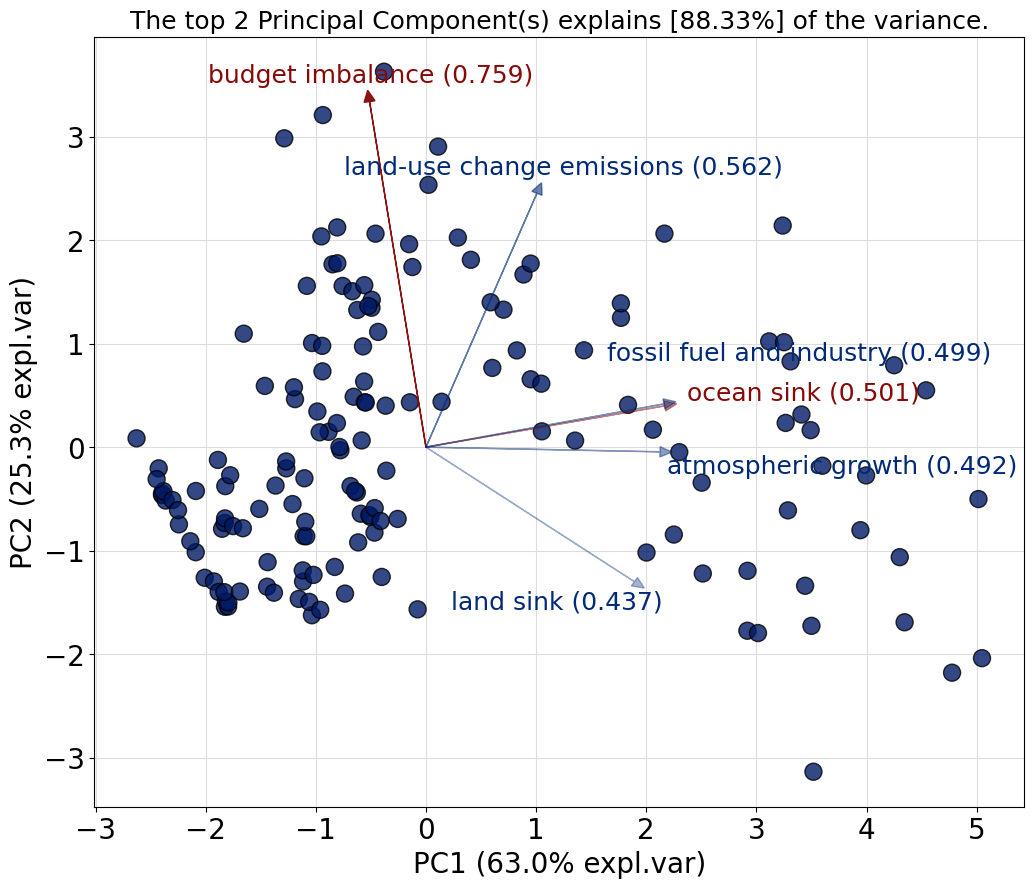

In [ ]:
# definir el modelo
model_carbon = pca(n_components=2, normalize=True)
out = model_carbon.fit_transform(carbon_sin_na)

# para hacer el biplot
fig, ax = model_carbon.biplot(label=True,
                              legend=True,
                              figsize=(12, 10))

Interpretación:

1. **Observaciones (puntos)**

- Cada punto representa un individuo (una fila de tu dataset original):

- Puntos cercanos: tienen valores similares en las variables originales.

- Puntos lejanos: son más distintos.

2. **Variables (flechas)**

 Las flechas representan las variables originales proyectadas en el nuevo espacio de componentes.

**Dirección**

 - Las variables que apuntan en la misma dirección están positivamente correlacionadas.

 - Si apuntan en direcciones opuestas → correlación negativa.

 - Si son casi perpendiculares → poca o ninguna correlación.

**Longitud de la flecha:**

 - Cuanto más larga es la flecha, mejor representada está la variable en el plano formado por las componentes mostradas.

 - Flechas cortas → variable menos explicada por las componentes mostradas.

**Ángulo entre flechas y ejes:**

 - Si una flecha apunta casi en la misma dirección que el eje PC1, esa variable tiene mucha carga (loading) en PC1.


PC1 explica el 63.0% de la varianza total.

PC2 explica el 25.3% de la varianza.

En conjunto, estas dos componentes explican el 88.33%, lo cual es excelente, ya que la mayoría de la información original está conservada.

** budget imbalance (0.759)**

- Mayor contribuyente a PC2, con una flecha larga y apuntando hacia arriba.

- Esta variable está menos correlacionada con otras (ángulo grande respecto a la mayoría).

- Su valor 0.759 indica que tiene alta carga en esa dirección.

- Las observaciones hacia la parte superior del gráfico tienen mayor desequilibrio presupuestario de carbono.

**land-use change emissions (0.562)**

- Apunta hacia la parte superior derecha.

- Tiene una buena contribución tanto a PC1 como a PC2.

- Probablemente relacionada positivamente con otras variables que apuntan en esa dirección.

**fossil fuel and industry (0.499)**

- Aporta mucho a PC1.

- Similar dirección a ocean sink y atmospheric growth, lo que sugiere correlación positiva entre esas tres variables.

**ocean sink (0.501)**

- Similar en dirección a fossil fuel and industry y atmospheric growth, lo que puede parecer contraintuitivo (porque el sumidero debería "compensar"), pero esto solo indica que estos valores aumentan juntos en los datos, no necesariamente causalidad positiva.

**atmospheric growth (0.492)**

- Contribuye fuertemente a PC1.

- Correlacionada con fossil fuel, ocean sink.

**land sink (0.437)**

- Apunta hacia abajo a la derecha.

- Menor influencia que las otras variables, pero aún significativa.

***En resumen***

- PC1 (63%) parece estar muy influido por emisiones fósiles, atmósfera, océano, y en menor medida por land sink.

- PC2 (25%) está dominado por el budget imbalance.

- Las observaciones hacia la derecha del gráfico son las que presentan valores más altos en emisiones fósiles, crecimiento atmosférico y sumideros oceánicos.

- Las observaciones más arriba tienen mayor desequilibrio en el presupuesto de carbono.


[07-10-2026 01:30:09] [pca.pca] [WARNING] Parameter <label> is deprecated and will not be supported in future version.
[07-10-2026 01:30:09] [pca.pca] [INFO] Plot PC1 vs PC2 with loadings.
[07-10-2026 01:30:09] [scatterd.scatterd] [INFO] Create scatterplot


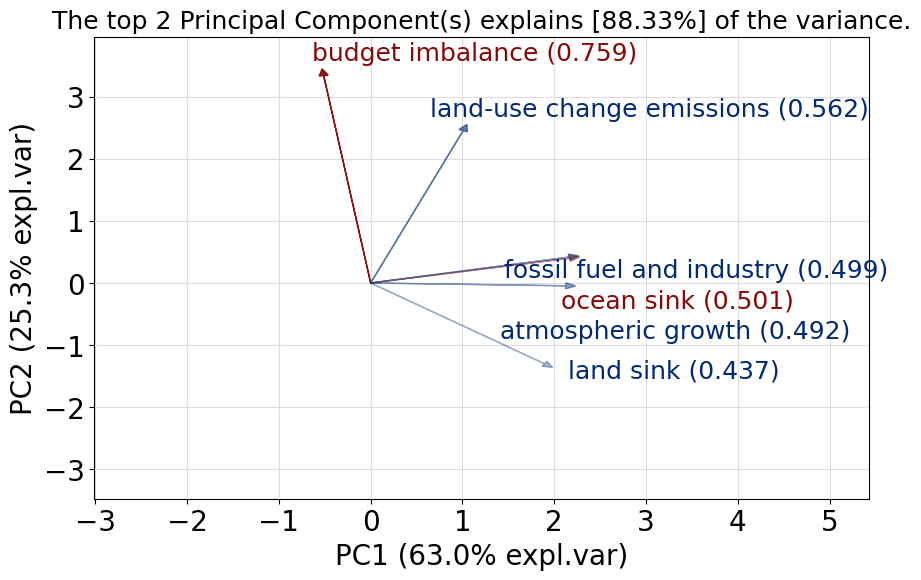

In [ ]:
# Si no queremos agregar los puntos
fig, ax = model_carbon.biplot(cmap=None,
                              label=False,
                              legend=False,
                              figsize=(10, 6))

# <FONT SIZE=5 COLOR="purple">  5. Ejemplo 3. Aplicado PCA + K-means </FONT>

Consideremos el conjunto de datos clásico de mnist de la librería keras. Este conjunto se usa mucho para redes neuronales y en internet hay muchos ejemplos con este conjunto.


Vamos a importar las librerías

In [2]:
# importamos keras para el conjunto de datos
import keras
from keras.datasets import fashion_mnist
# importamos kmeans
from sklearn.cluster import KMeans

El conjunto de datos que vamos a usar, viene distribuido en dos partes ya que nos sirve para problemas de clasificación.

In [3]:
(X_train,y_train), (X_test,y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
X_train.shape

(60000, 28, 28)

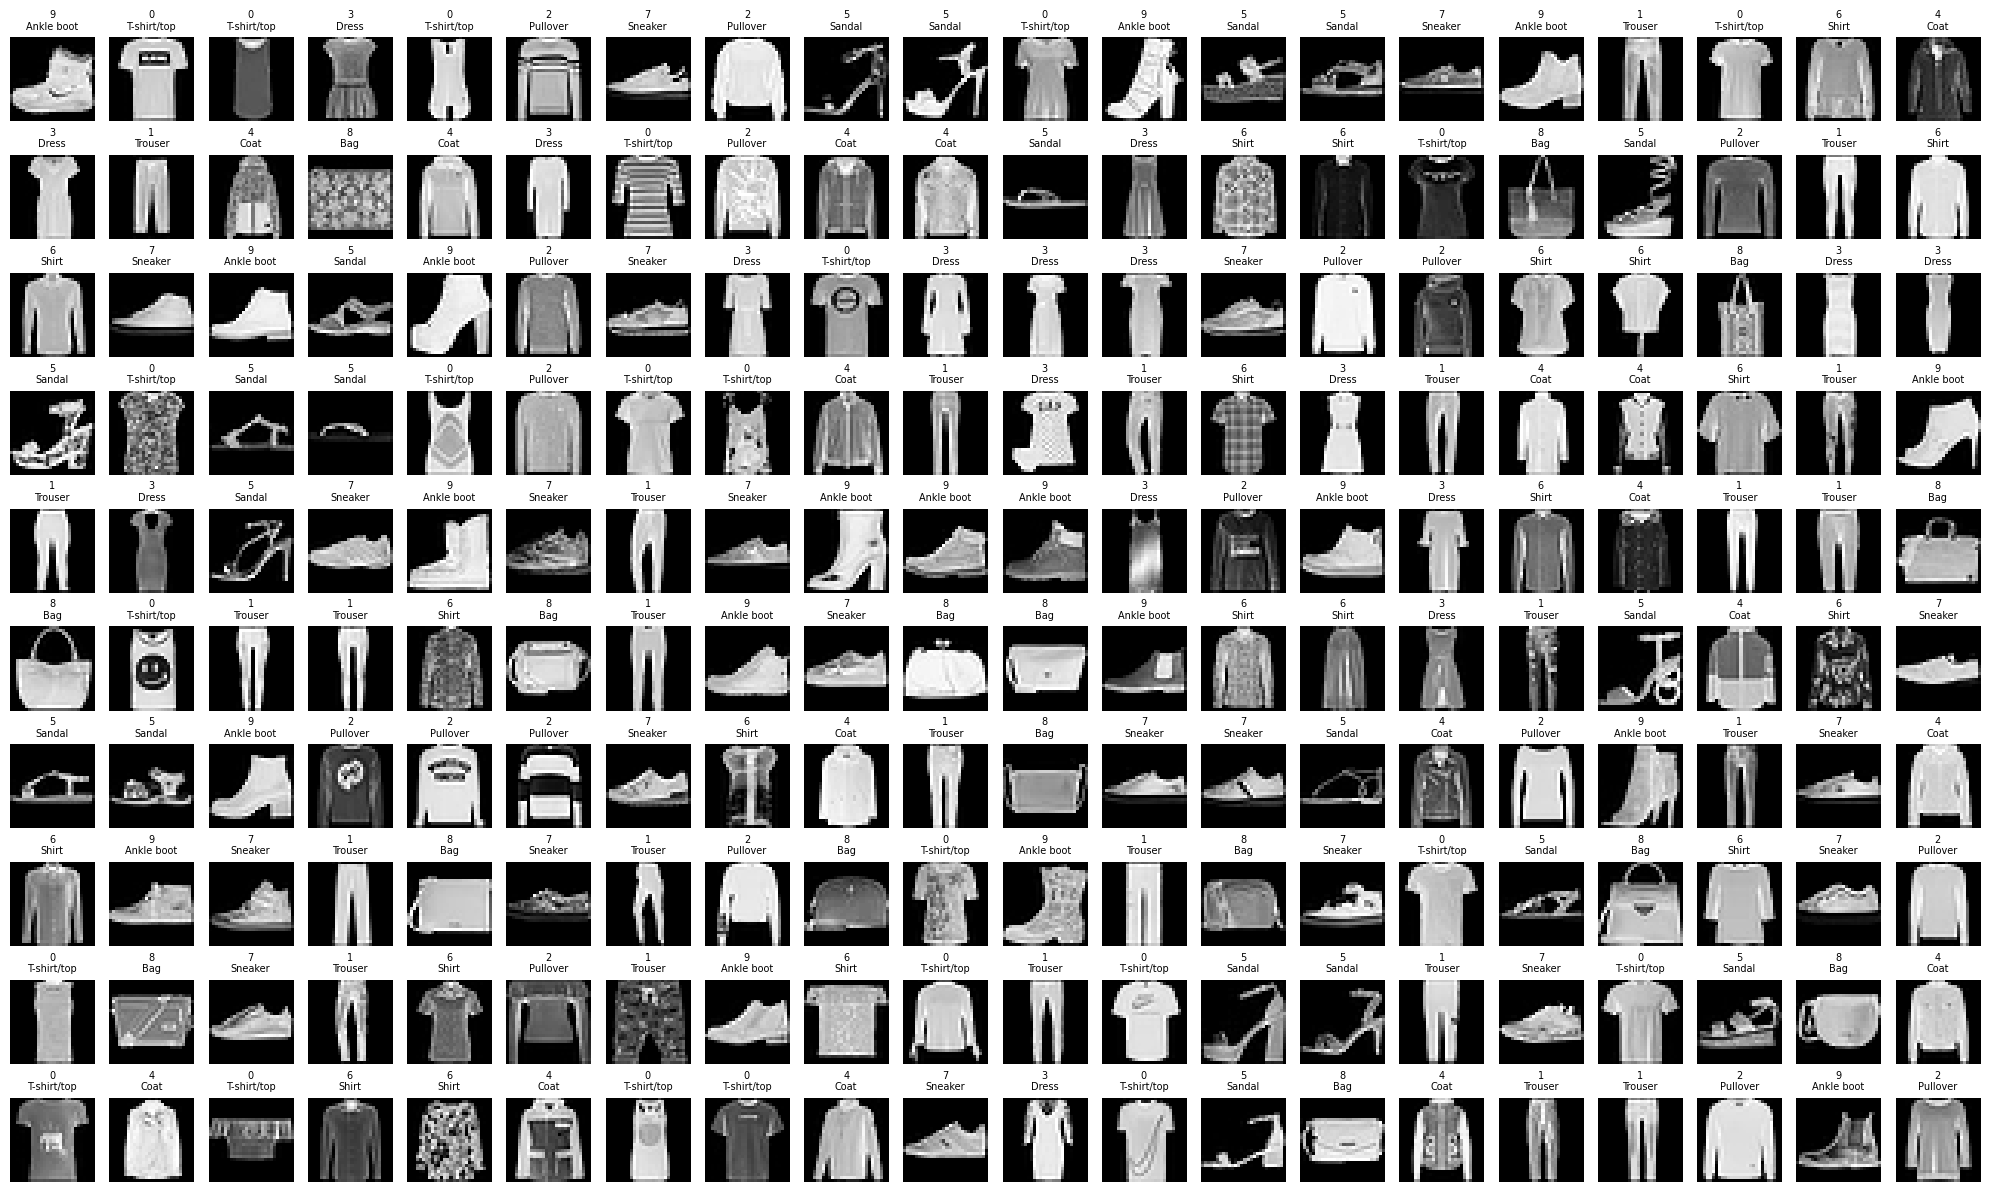

In [5]:
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist

# Cargar Fashion MNIST
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Nombres de las clases
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Crear figura
plt.figure(figsize=(20, 12))

# Mostrar 200 imágenes
for i in range(200):
    plt.subplot(10, 20, i + 1)

    plt.imshow(x_train[i], cmap="gray")

    plt.title(
        f"{y_train[i]}\n{class_names[y_train[i]]}",
        fontsize=7
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

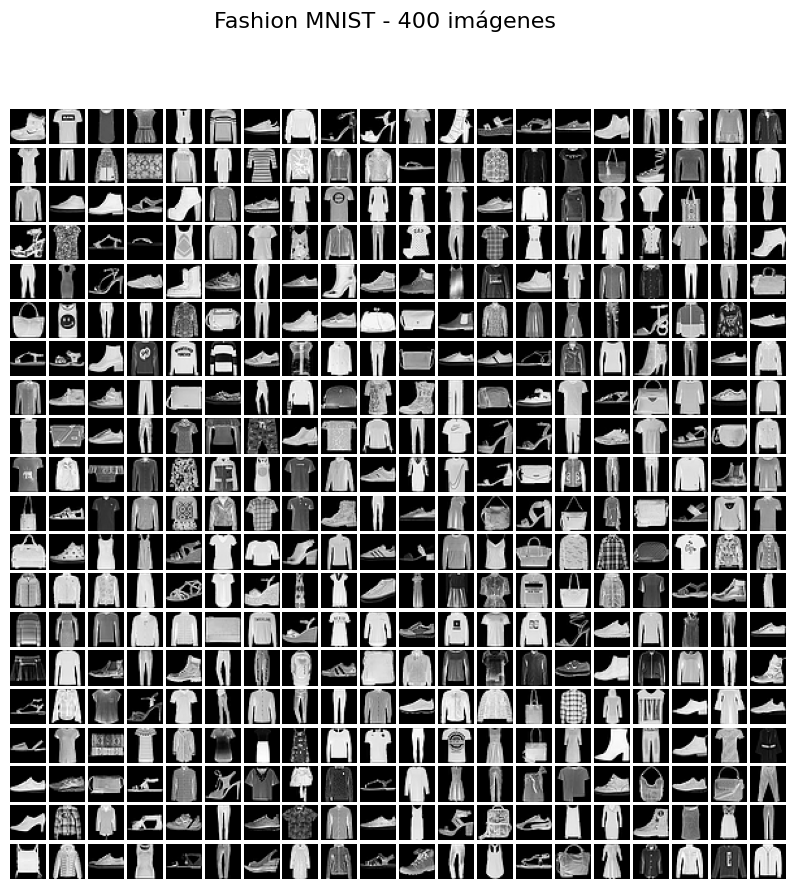

In [6]:
# Seleccionar 400 imágenes (puedes hacer shuffle si quieres aleatoriedad)
n_images = 400
images = X_train[:n_images]

# Crear figura y ejes
fig, axes = plt.subplots(20, 20, figsize=(10, 10))

# Eliminar espacios entre celdas
plt.subplots_adjust(wspace=0.1, hspace=0.1)

# Rellenar la cuadrícula
for i in range(20):
    for j in range(20):
        idx = i * 20 + j
        axes[i, j].imshow(images[idx], cmap='gray')
        axes[i, j].axis('off')  # Ocultar ejes

plt.suptitle("Fashion MNIST - 400 imágenes", fontsize=16)
plt.show()

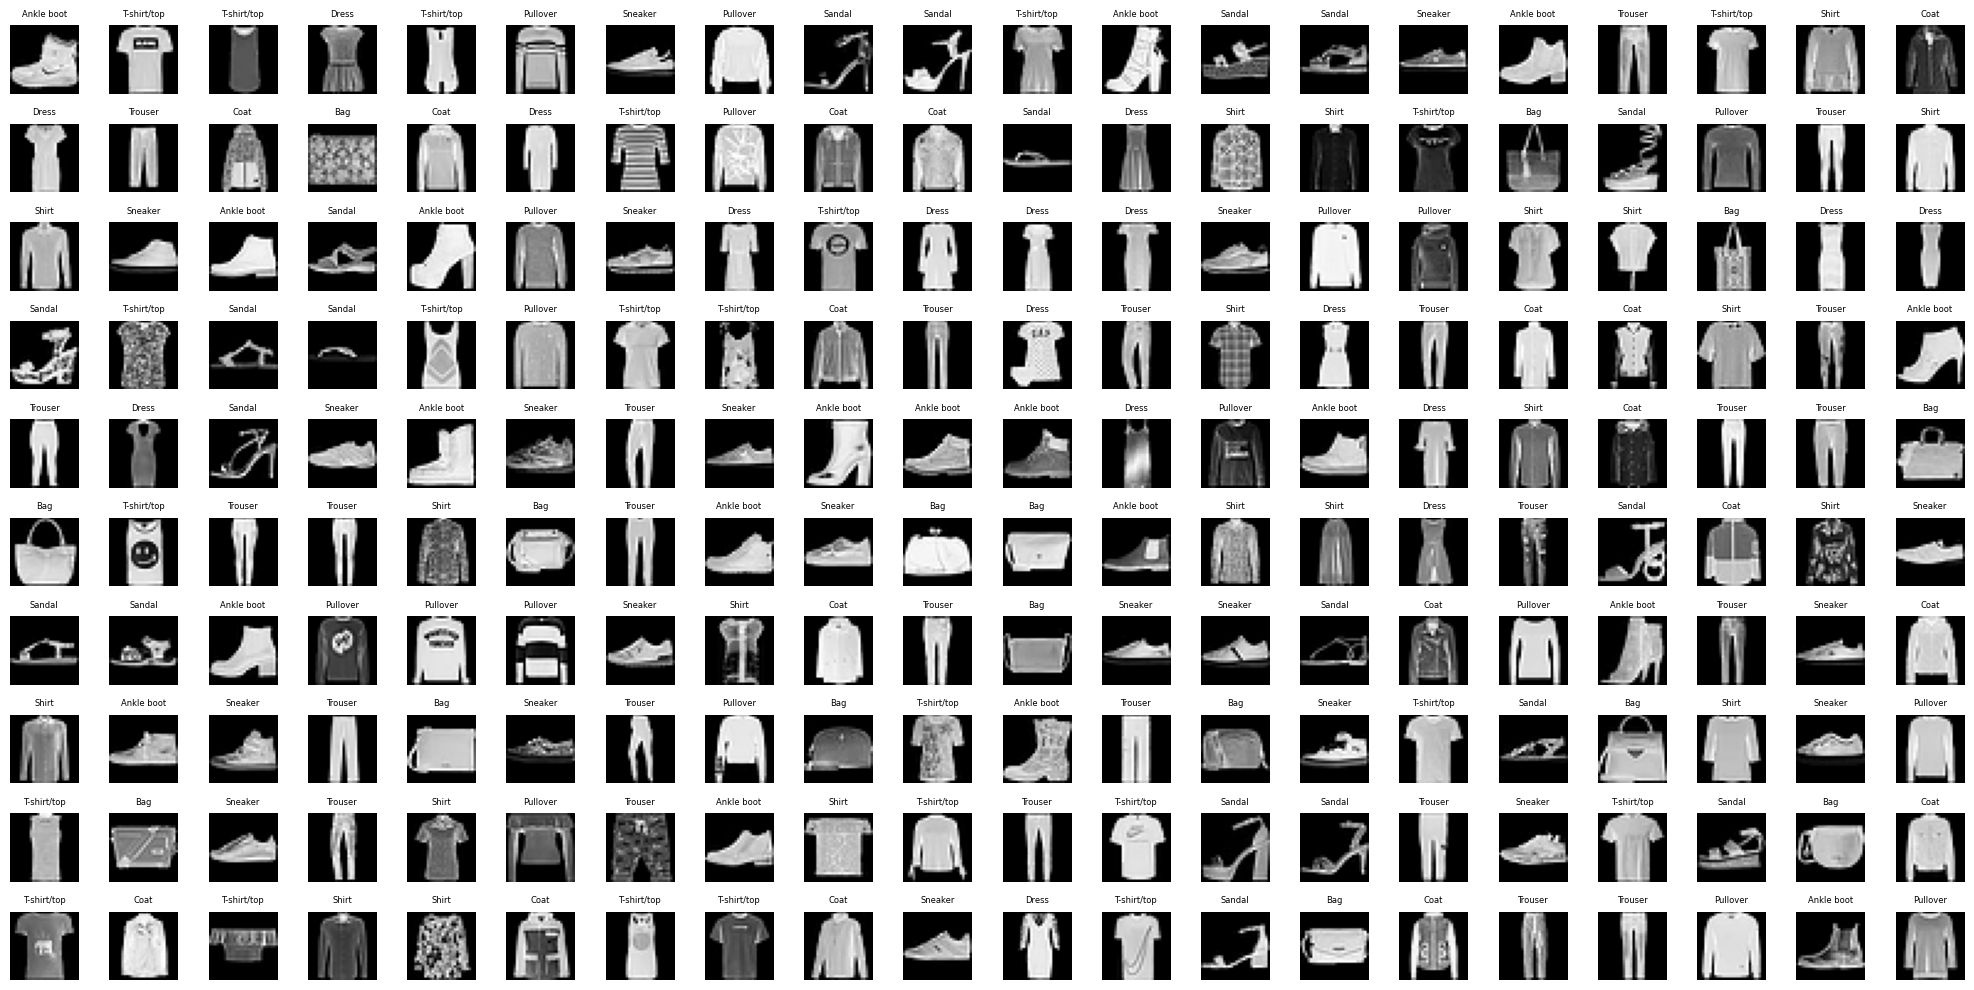

In [7]:
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist

# Cargar datos
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Nombres de las clases
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Mostrar las primeras 200 imágenes
fig, axes = plt.subplots(10, 20, figsize=(20, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i], cmap='gray')
    ax.set_title(class_names[y_train[i]], fontsize=6)
    ax.axis('off')

plt.tight_layout()
plt.show()

Para el propósito de este ejercicio solamente vamos a tomar el conjunto de entrenamiento.


In [8]:
# debemos redimensionar los datos. como es 28 x 28 = 784
imagenes = X_train.reshape(-1,X_train.shape[1]*X_train.shape[2])
imagenes.shape

(60000, 784)

In [9]:
60000*784

47040000

In [10]:
# llamaremos y a los labels
y = y_train
y.shape

(60000,)

La variable y está dada de forma numérica, pero en realidad es una codificación de lo siguiente:

0 --->  Tshirt

1 --->  Trouser

2 --->  Pullover

3 --->  Dress

4 --->  Coat

5 --->  Sandal

6 --->  Shirt

7 --->  Sneaker

8 --->  Bag

9 --->  Ankle Boot

Visualicemos algunos elementos

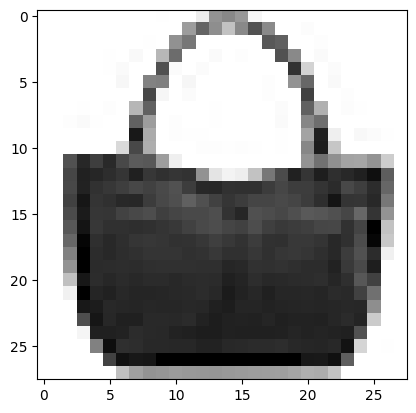

np.uint8(8)

In [11]:
# podemos cambiar el número n
n= 100
plt.imshow(imagenes[n].reshape(X_train.shape[1], X_train.shape[2]), cmap = plt.cm.binary)
plt.show()
y[n]

La idea del ejercicio es reducir la dimensionalidad para luego aplicar k-means y hacer el proceso de clustering

## <FONT SIZE=4 COLOR="blue">  5.1 Aplicar PCA </FONT>

In [ ]:
# primero debeos escalar los datos
imagenes_est = StandardScaler().fit_transform(imagenes)

In [ ]:
from sklearn.decomposition import PCA
#vamos a definir la varianza que queremos acumular (98%)
varianza = 0.98
pca = PCA(varianza)

In [ ]:
#entreno el PCA
pca.fit(imagenes_est)

PCA(n_components=0.98)

Veamos el número de componentes

In [ ]:
pca.n_components_

np.int64(420)

Ahora, vamos a transformar nuestros datos

In [ ]:
#Transformar los datos de acuerdo con el PCA definido
imagenes_pca = pca.transform(imagenes_est)

In [ ]:
imagenes_est.shape

(60000, 784)

In [ ]:
# dimensión después del PCA
imagenes_pca.shape

(60000, 420)

In [ ]:
#Vamos a definir la transformada inversa para poder visualizar los elementos a partir de la transformación
approx = pca.inverse_transform(imagenes_pca)
approx.shape

(60000, 784)

Vamos a reconstruir las imágenes usando menos información

8


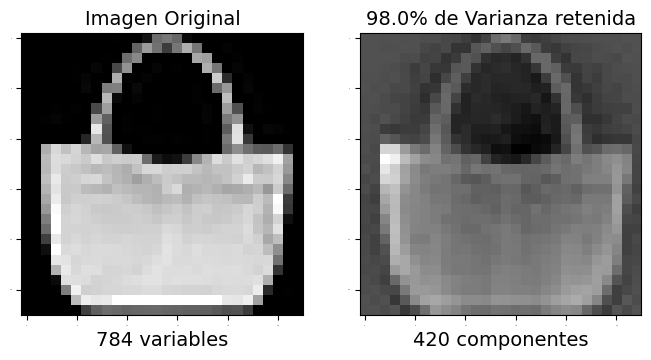

In [ ]:
#Reconstrucción de las imágenes con menos información
plt.figure(figsize=(8,4));

# un valor de n para el objeto del dataframe
n = 100

# Imagen Original
plt.subplot(1, 2, 1);
plt.imshow(imagenes[n].reshape(X_train.shape[1],X_train.shape[2]), # basicamente X_train.shape[1] = 28
           cmap = plt.cm.gray,);
plt.xlabel(str(imagenes.shape[1])+" variables", fontsize = 14)
plt.title("Imagen Original", fontsize = 14);

# Imagen con las componentes
plt.subplot(1, 2, 2);
plt.imshow(approx[n].reshape(X_train.shape[1], X_train.shape[2]),
           cmap = plt.cm.gray,);
plt.xlabel(str(imagenes_pca.shape[1]) +" componentes", fontsize = 14)
plt.title(str(varianza * 100) + '% de Varianza retenida', fontsize = 14);

print(y_train[n])

## <FONT SIZE=4 COLOR="blue">  5.2 Aplicar K-means </FONT>


In [ ]:
k_means = KMeans(init = "k-means++",
                 n_clusters = 10,
                 n_init = 35)

**init="k-means++"**

- Utiliza el algoritmo KMeans++ para elegir los centroides iniciales de forma inteligente.

- Mejora la estabilidad del algoritmo y reduce el riesgo de caer en un mal mínimo local.

Es mejor que usar centroides aleatorios (init="random").

**n_clusters=10**

- Es el número de grupos y tomaremos 10 por las clases que hay en el conjunto.

**n_init=35**

- Significa que el algoritmo KMeans se ejecutará 35 veces con diferentes centroides iniciales.

- Luego elegirá la mejor solución (la que tenga el menor error de agrupamiento, o inercia).

- Más repeticiones = más probabilidades de encontrar una buena solución.

In [ ]:
#vamos a entrenar el modelo de kmeans para nuestros datos_pca
k_means.fit(imagenes_pca)

KMeans(n_clusters=10, n_init=35)

In [ ]:
# recomendación -- guardar el modelo
import joblib
# guardar
joblib.dump(k_means, 'kmeans_model2.joblib')
# cargar
#k_means = joblib.load('kmeans_model.joblib')

['kmeans_model2.joblib']

In [ ]:
# verificamos los labels o etiquetas
k_means_labels = k_means.labels_
print("La lista de los labels de los clusters son " + str(np.unique(k_means_labels)))

La lista de los labels de los clusters son [0 1 2 3 4 5 6 7 8 9]


In [ ]:
# número de labels
num_lab = len(np.unique(k_means_labels))

#Veamos los elementos que pertenecen a cada label o etiqueta
cluster_index= [[] for i in range(num_lab)]
for i, label in enumerate(k_means_labels,0):
    for n in range(num_lab):
        if label == n:
            cluster_index[n].append(i)
        else:
            continue

In [ ]:
# veamos los primeros 10 indices algunos label
print("registros del label 0", cluster_index[0][0:10])
print("registros del label 1", cluster_index[1][0:10])
print("registros del label 2", cluster_index[2][0:10])

registros del label 0 [4, 16, 21, 31, 38, 50, 51, 58, 59, 69]
registros del label 1 [3, 22, 28, 35, 36, 37, 54, 57, 61, 72]
registros del label 2 [0, 15, 42, 60, 89, 90, 93, 107, 111, 122]


Ahora, vamos a visualizar algunos clusters

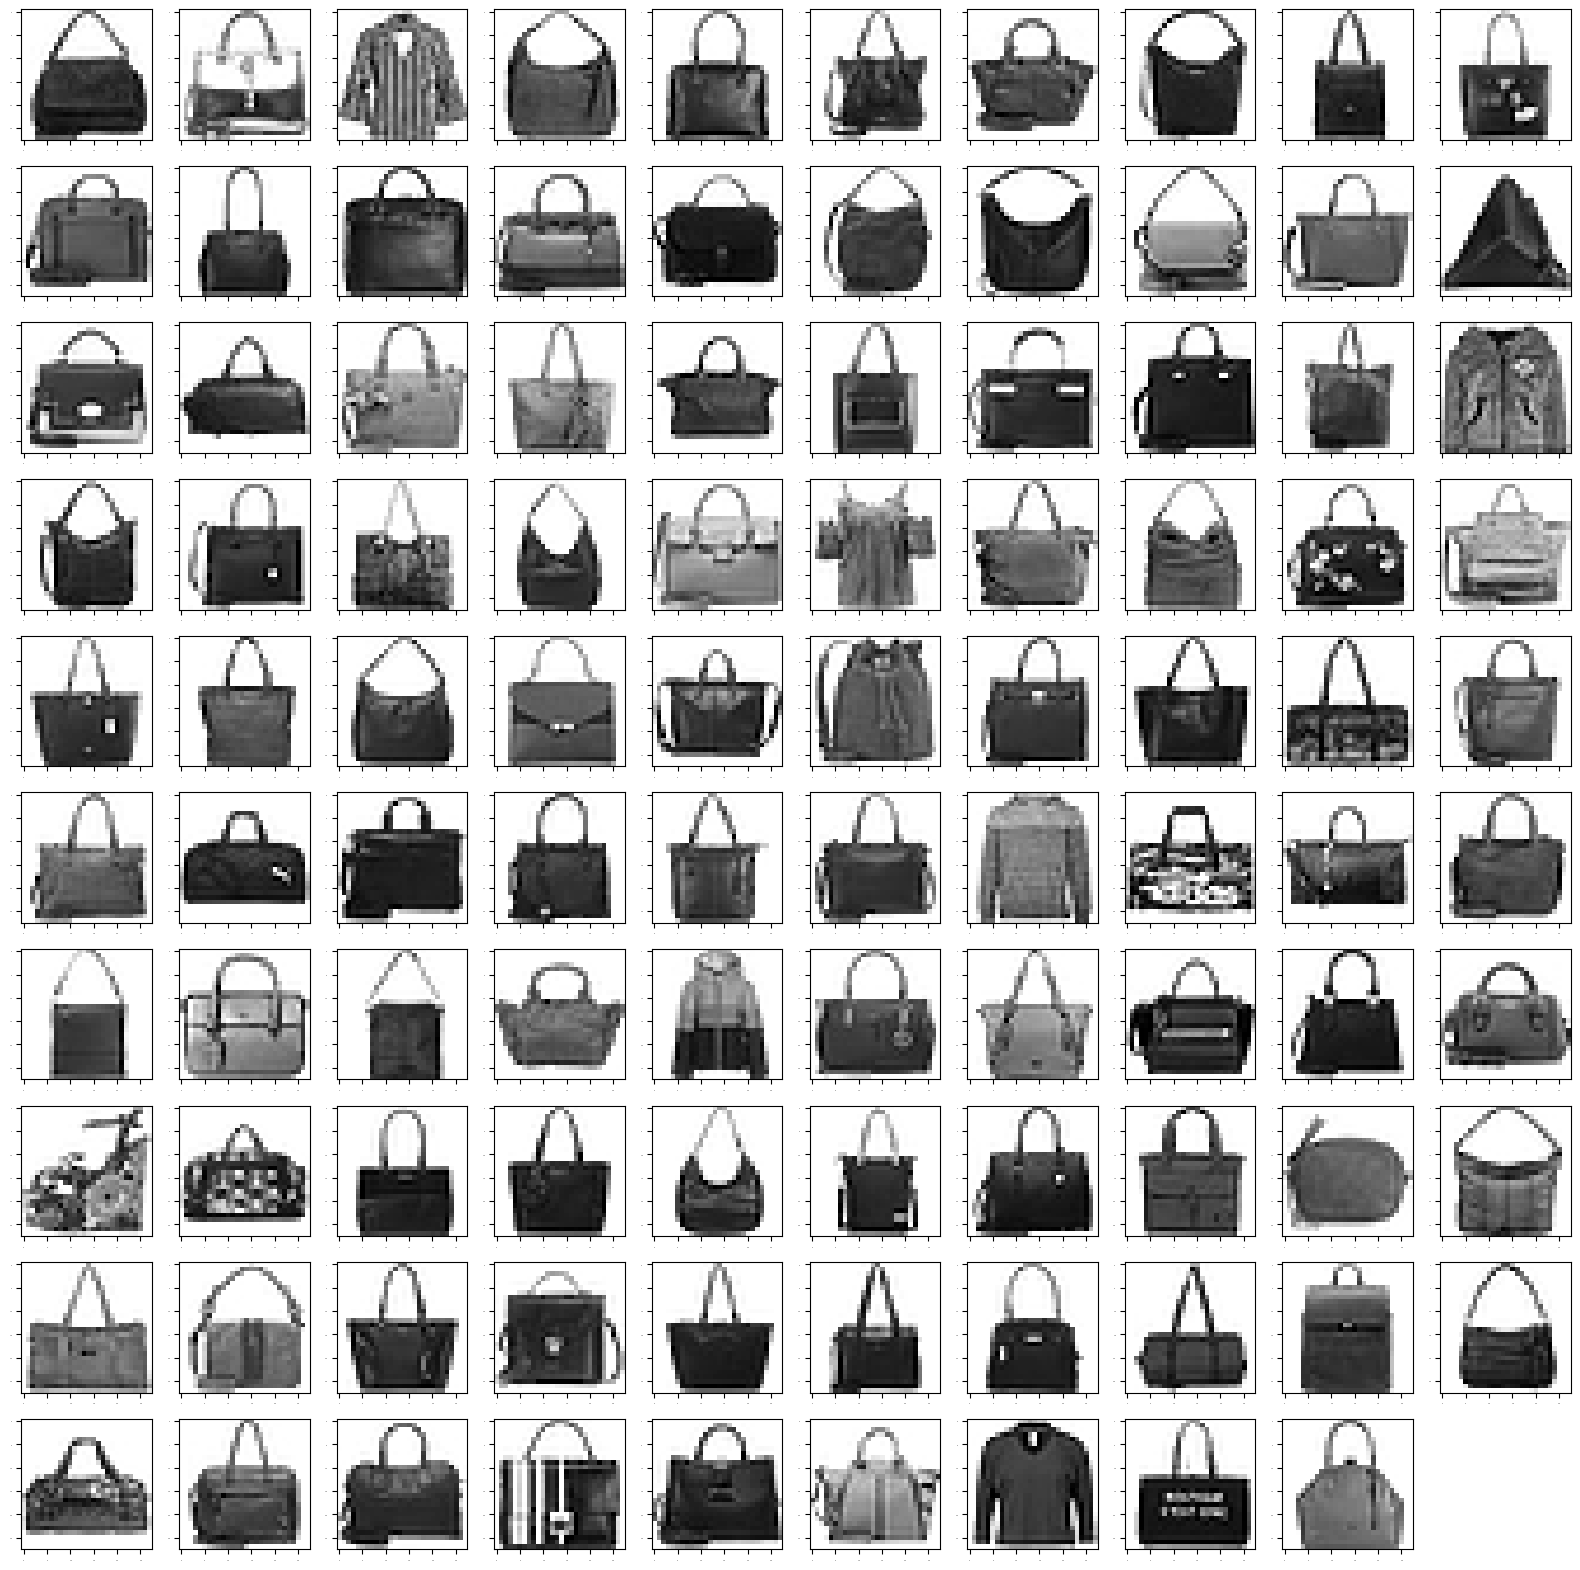

In [ ]:
#Visualización de algunos clusters
# establecemos el tamaño de la figura
plt.figure(figsize=(20,20));
# definimos el número de cluster que queremos visualizar
clust = 3
# definimos el número de elementos a visualizar
num = 100
for i in range(1,num):
    # número de filas, número de columnas por filas, iterador
    plt.subplot(10, 10, i);
    plt.imshow(imagenes[cluster_index[clust][i+500]].reshape(X_train.shape[1], X_train.shape[2]), cmap = plt.cm.binary);

plt.show()

In [ ]:
Y_clust = [[] for i in range(num_lab)]
for n in range(num_lab):
    # Y_clust[0] contiene el arreglo de la categoria correcta de y_train
    Y_clust[n] = y[cluster_index[n]]
    assert(len(Y_clust[n]) == len(cluster_index[n]))

In [ ]:
#cuenta el número de cada categoria en cada cluster
def counter(cluster):
    unique, counts = np.unique(cluster, return_counts=True)
    label_index = dict(zip(unique, counts))
    return label_index

In [ ]:
label_count= [[] for i in range(num_lab)]
for n in range(num_lab):
    label_count[n] = counter(Y_clust[n])
# número de items de cada categoría enel cluster 1.
label_count[1]

{np.uint8(0): np.int64(1671),
 np.uint8(1): np.int64(154),
 np.uint8(2): np.int64(1744),
 np.uint8(3): np.int64(653),
 np.uint8(4): np.int64(1077),
 np.uint8(5): np.int64(35),
 np.uint8(6): np.int64(2089),
 np.uint8(8): np.int64(522),
 np.uint8(9): np.int64(52)}

In [ ]:
# diccionario con los nombres de las clases
class_names = {0:'T-shirt/top',
               1:'Trouser',
               2:'Pullover',
               3:'Dress',
               4:'Coat',
               5:'Sandal',
               6:'Shirt',
               7:'Sneaker',
               8:'Bag',
               9:'Ankle boot'}

# definimos una función para que me represente gráficamente las frecuencias
def plotter(label_dict):
    plt.figure(figsize=(8,5))

    plt.bar(range(len(label_dict)), list(label_dict.values()), align='center')

    etiquetas = [class_names[i] for i in label_dict]

    plt.xticks(
        range(len(label_dict)),
        etiquetas,
        rotation=45,
        ha='right',
        fontsize=14   # Tamaño de las etiquetas
    )

    plt.show()

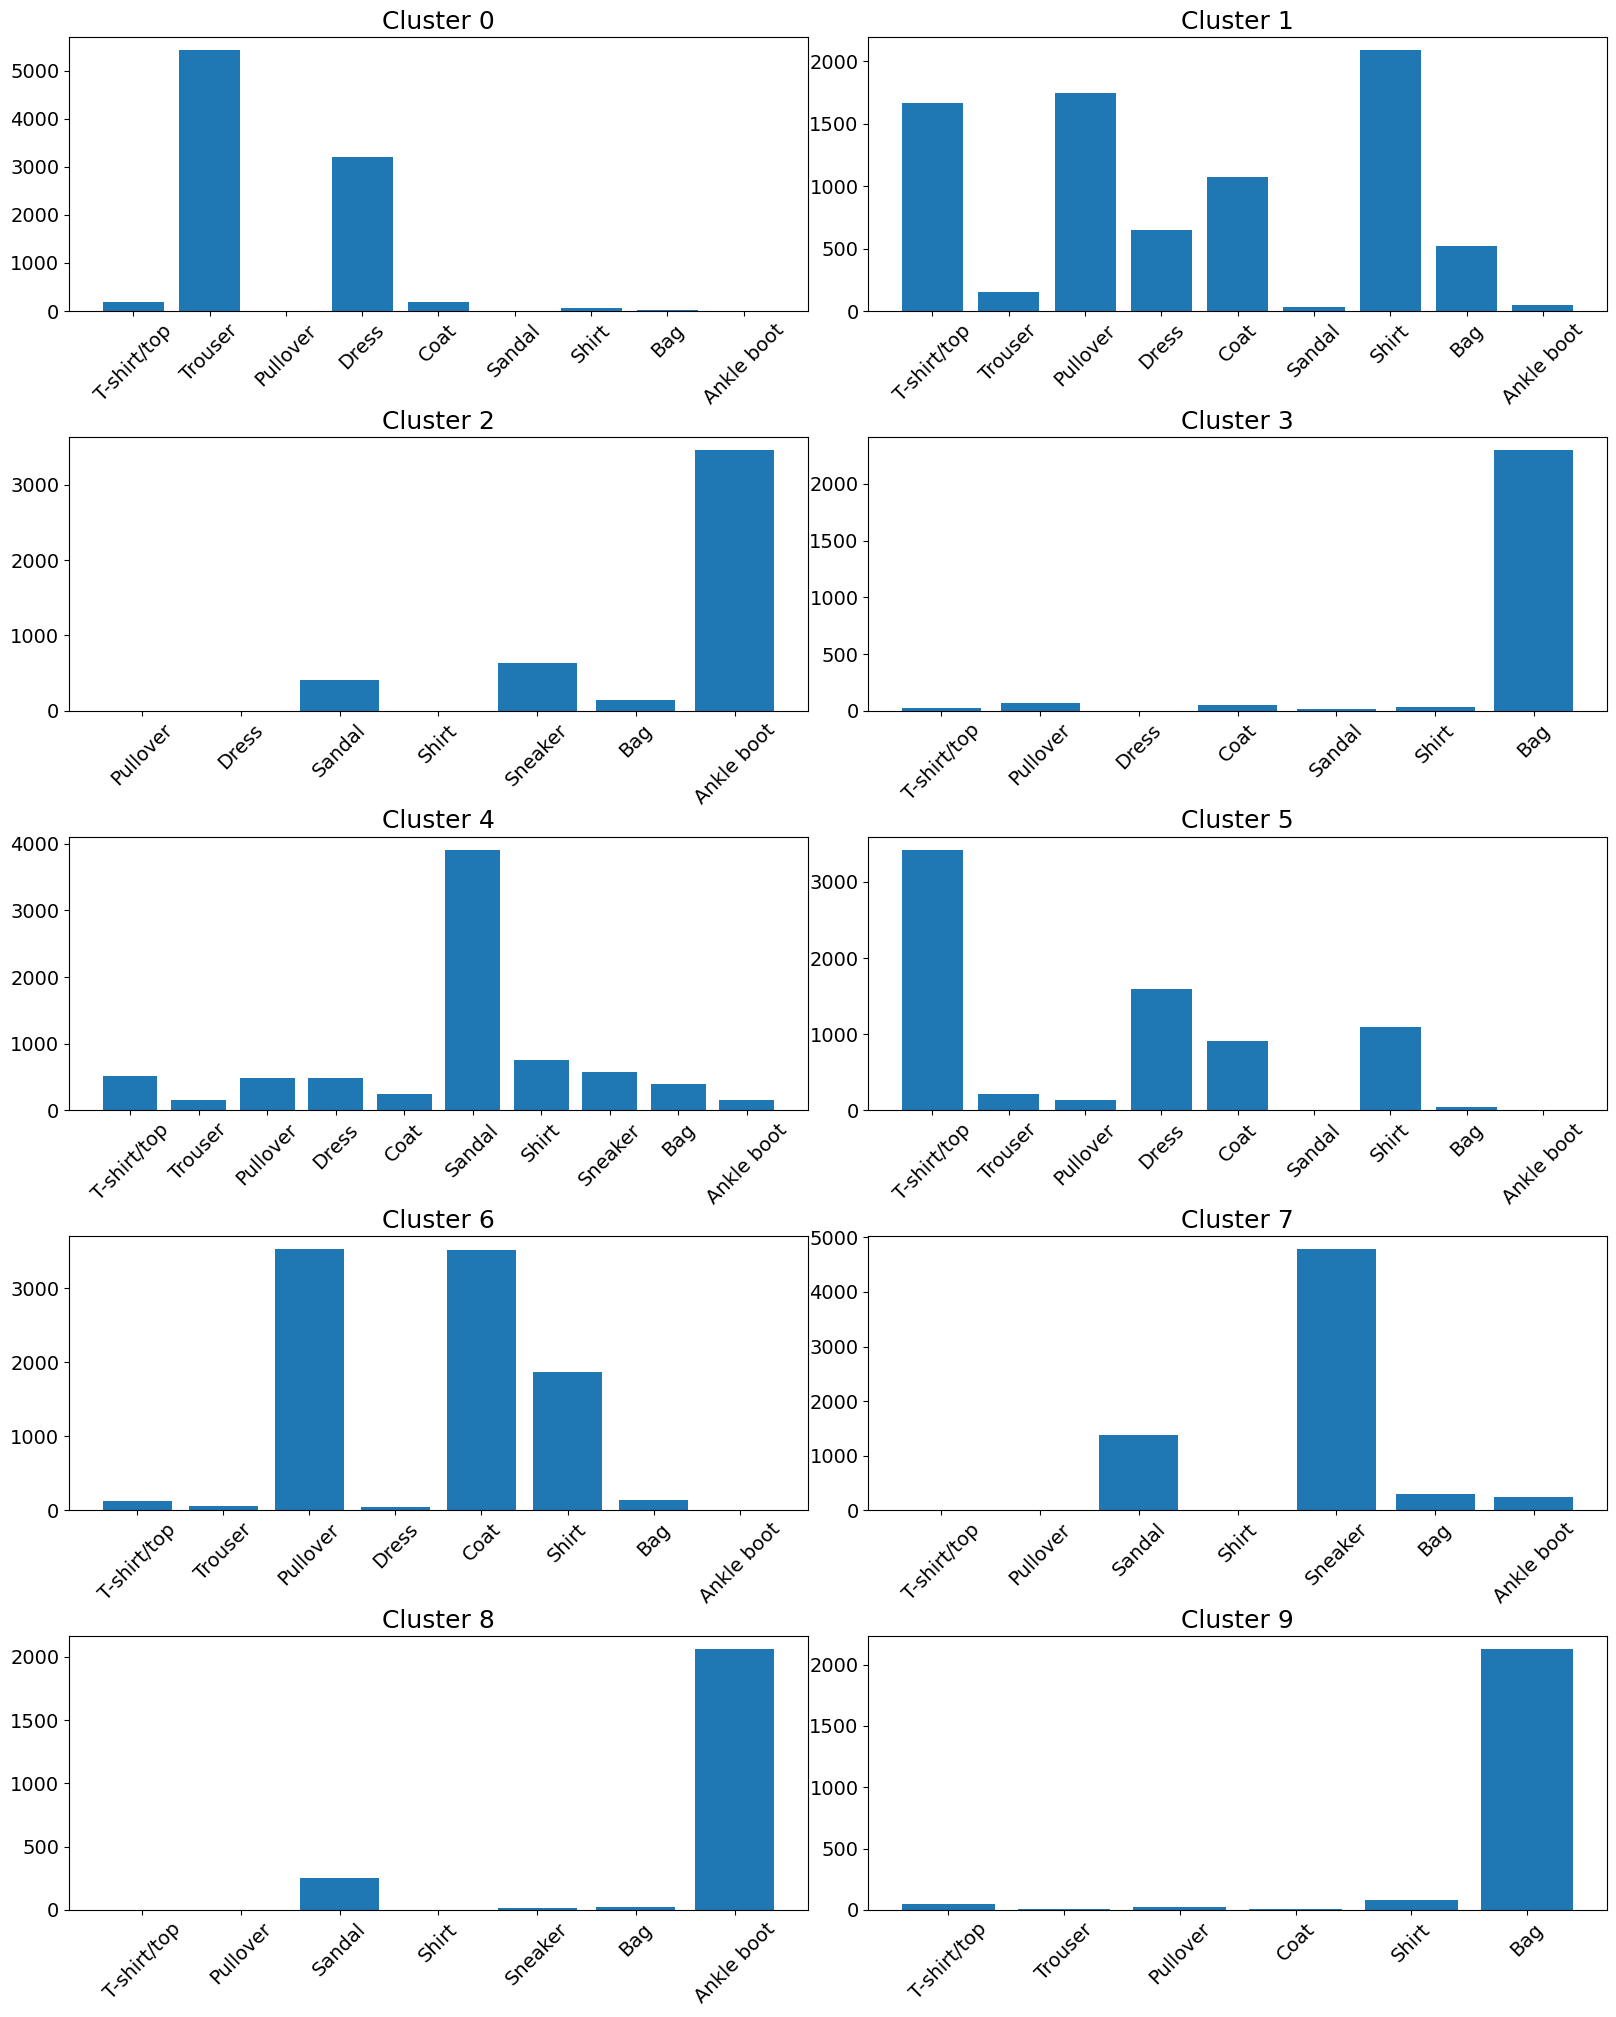

In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(16, 20))
axes = axes.flatten()

for n in range(10):

    datos = label_count[n]

    clases = [class_names[k] for k in datos.keys()]
    frecuencias = list(datos.values())

    axes[n].bar(clases, frecuencias)

    # Título más grande
    axes[n].set_title(f"Cluster {n}", fontsize=18)

    # Labels del eje X más grandes
    axes[n].tick_params(
        axis="x",
        rotation=45,
        labelsize=14
    )

    # Números del eje Y más grandes
    axes[n].tick_params(
        axis="y",
        labelsize=14
    )

plt.tight_layout()
plt.show()